# 04 - A cheaper TabPFN (v3, v4; small and medium datasets)

TabPFN on QUANT's features is the most accurate classifier of notebook 02, but about 30 times slower than ExtraTrees
(the original QUANT classifier). Notebook 03 showed that the cheapest extra feature set, the lag-d differences alone
(v2-lagd), is also the best one. This notebook looks for a cheaper TabPFN: it compares TabPFN versions (cost settings
and feature sets), picks one, and compares it with the two v1 references: **QUANT + ExtraTrees** (the original method)
and **QUANT + TabPFN** with its default settings.

| Version | What changes | Files |
|---|---|---|
| **v3-quant** | TabPFN on QUANT's features, with other cost settings (table below), one file per setting; `-cache`: TabPFN's model built once (section 7) | `v3-quant_tabpfn-e{passes}f{features}[-c1000][-cache]_smoke-{small,medium}_allcores-gpu.csv` |
| **v3-lagd** | TabPFN on v2-lagd's features (all QUANT features + the best lag-d features): 2 passes x 200 features (the run also has the other three classifiers, compared in notebook 03), 1 pass x 500, 400, 300, 200 or 100 features, and with the cache | `v3-lagd_tabpfn-{e2f200,e1f500,...,e1f100}[-cache]_smoke-{small,medium}_allcores-gpu.csv` |
| **v4-first** | the first version of a feature extractor for TabPFN (`quant_tabpfn.py`, `--quant tabpfn`), on v2-lagd's settings with the cache; `--feature_log` adds the feature classes (sections 8-10) | `v4-first_tabpfn-{e1f300,e2f200}-cache_smoke-{small,medium}_allcores-gpu.csv` and `..._features.csv` |
| **v4** | about 450 features (the extractor with 4 levels, 2 quantiles per piece, lag-d 4 and 16), TabPFN's features picked by ExtraTrees, ANOVA or both (section 10) | `v4_tabpfn-{e1f300,e2f200}-{extratrees,anova,both}_smoke-{small,medium}_allcores-gpu.csv` and `..._features.csv` |
| **v4-nofilter** | about 252 features (3 levels, 3 quantiles per piece, lag-d 4 and 16), no filtering: TabPFN gets all of them (section 10) | `v4-nofilter_tabpfn-{e1,e2}_smoke-{small,medium}_allcores-gpu.csv` and `..._features.csv` |
| **v4-wide** | about 1,800 features (v4-first's extractor), no lag-d filter, ANOVA alone picks TabPFN's 200; 2 passes (section 10) | `v4-wide_tabpfn-e2f200-anova_smoke-{small,medium}_allcores-gpu.csv` and `..._features.csv` |

TabPFN's three cost settings, which v1 left at their defaults:

| Setting | What it does | Values |
|---|---|---|
| ensemble size (passes) | TabPFN predicts several times on slightly different versions of the data and averages | 8 (default), 4, 2, 1 |
| feature budget | how many of the most important features TabPFN gets (ranked by ExtraTrees on the training set) | 500 (v1), 400, 300, 200, 100 |
| training context | at most this many training cases (stratified random subset); TabPFN compares every test case with all of them | all (v1), 1,000 (medium only) |

Every run uses `improvedQuant/features/run.py`: `--tabpfn_estimators` (the passes), `--tabpfn_features`,
`--tabpfn_context` (0 = all training cases) and, in section 7, `--tabpfn_cache`; the sweep uses QUANT's features
only (no `--lags`, no `--extra`), the v3-lagd runs add `--lags 2,4,8,16 --lag_filter separate`.

Names: `tabpfn-e2f200` = 2 passes, 200 features, all training cases; `-c1000` = at most 1,000 training cases (run
only where the training set is larger: PhalangesOutlinesCorrect and AconityMINIPrinterLargeEq, so never on the small
datasets). `tabpfn-e8f500` is v1's TabPFN. The reference for both lists is the v1 run of notebook 03 (ExtraTrees and
TabPFN on QUANT's features), and the v2-lagd run of notebook 03 gives TabPFN's default on the v2-lagd features.

| Setting | Value |
|---|---|
| datasets | **small** (`smoke-small.txt`): Coffee, GunPoint, ItalyPowerDemand, ECG200, Beef (28 to 100 training cases); **medium** (`smoke-medium.txt`): ChlorineConcentration, UWaveGestureLibraryX, SharePriceIncrease, PhalangesOutlinesCorrect, AconityMINIPrinterLargeEq (467 to 2,403 training cases) |
| resamples | 0, 1, 2 (15 runs per configuration and list) |
| hardware | all CPU cores, TabPFN, XGBoost and CatBoost on the GPU |
| seed | 0 |

**How the files are produced:** see `experiments.md`, v3 and v4.

- **Sections 2, 3** - the v3 sweep: accuracy and cost of each configuration.
- **Section 4** - all TabPFN versions on both feature sets, and the cheap version used in section 5.
- **Section 5** - the chosen TabPFN vs QUANT + ExtraTrees and vs QUANT + TabPFN (v1).
- **Section 6** - the training-context cap (medium datasets only).
- **Section 7** - TabPFN's model cache: the same runs without rebuilding the model every time.
- **Section 8** - a feature extractor for TabPFN (`quant_tabpfn.py`) vs QUANT's original one.
- **Section 9** - which features are produced, kept by the filter and given to TabPFN.
- **Section 10** - v4: about 450 features, and three ways to pick TabPFN's features; v4-nofilter: about 252
  features, no filtering; v4-wide: about 1,800 features, ANOVA alone.
- **Section 11** - where we started and where we ended: the v1 references vs the best cheap TabPFN (v4 + both),
  the version run on all 142 datasets in notebook 06.

All results are shown as plots; times are in seconds on linear axes. Every section shows the small datasets first,
then the medium ones.

Caveat: a smoke test (5 datasets x 3 resamples per list), a first signal, not a conclusion.

## 1. Settings and data

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import (BETTER, COLORS, EQUAL, GRID, MUTED, RESULTS_DIR, TEXT, VERSION_COLORS, WORSE, load_runs, signed,
                    style, wdl_counts)

style()
GROUPS = ["small", "medium"]           # the two dataset lists; every section shows both
key = ["dataset", "resample"]          # one run = one dataset and one resample

def load(name):
    """The finished runs of a file in results/ (with the time columns of common.load_runs)."""
    d = load_runs(RESULTS_DIR / name)
    return d[d["status"] == "ok"]

def lagd_file(config, group):
    """The file of a TabPFN configuration on v2-lagd's features (the default: the v2-lagd run of notebook 03)."""
    return (f"v2-lagd_smoke-{group}_allcores-gpu.csv" if config == "tabpfn-e8f500"
            else f"v3-lagd_{config}_smoke-{group}_allcores-gpu.csv")

LAGD_CONFIGS = ["tabpfn-e8f500", "tabpfn-e2f200"] + [f"tabpfn-e1f{k}" for k in [500, 400, 300, 200, 100]]
# the v3 sweep configurations (TabPFN on QUANT's features, one file each), and how they are named in the plots
ALL_CONFIGS = ["tabpfn-e8f500", "tabpfn-e4f500", "tabpfn-e2f500", "tabpfn-e1f500", "tabpfn-e8f200", "tabpfn-e2f200",
               "tabpfn-e8f500-c1000", "tabpfn-e2f500-c1000"]

def sweep_file(config, group, tag=""):
    """The file of a sweep configuration; tag "-cache": the same configuration with TabPFN's model cache."""
    return RESULTS_DIR / f"v3-quant_{config}{tag}_smoke-{group}_allcores-gpu.csv"

SWEEP, V1, LAGD = {}, {}, {}
for group in GROUPS:
    # every configuration file of this list (the context cap only exists for the medium datasets), each run
    # named after its configuration
    frames = [load(sweep_file(c, group).name).assign(classifier=c) for c in ALL_CONFIGS if sweep_file(c, group).exists()]
    SWEEP[group] = pd.concat(frames, ignore_index=True)
    V1[group] = load(f"v1_smoke-{group}_allcores-gpu.csv")        # v1: all four classifiers on QUANT's features
    LAGD[group] = {config: load(lagd_file(config, group)) for config in LAGD_CONFIGS}

def sweep_runs(group):
    """The sweep's TabPFN runs, with v1's ExtraTrees runs as the reference ("extratrees")."""
    v1 = V1[group]
    return pd.concat([SWEEP[group], v1[v1["classifier"] == "extratrees"]], ignore_index=True)

FEATURE_COLORS = {"QUANT": VERSION_COLORS["v1"], "v2-lagd": VERSION_COLORS["v2-lagd"]}     # TabPFN on v1's / v2-lagd's features

def group_title(fig, group, top=0.95):
    """Name the dataset list above a figure."""
    fig.suptitle(f"{group} datasets", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, top))

def stacked_wdl(ax, names, counts, title):
    """Horizontal stacked bars: the better / equal / worse counts of every name, each part labelled with its count."""
    y = np.arange(len(names))[::-1]
    left = np.zeros(len(names))
    for k, (label, color) in enumerate([("better", BETTER), ("equal", EQUAL), ("worse", WORSE)]):
        values = np.array([c[k] for c in counts], dtype=float)
        bars = ax.barh(y, values, left=left, color=color, edgecolor="white", label=label)
        ax.bar_label(bars, labels=[f"{v:.0f}" if v > 0 else "" for v in values], label_type="center", fontsize=9,
                     color=TEXT if color == EQUAL else "white")
        left += values
    ax.set_yticks(y, names)
    ax.set_xlabel("runs")
    ax.set_title(title, loc="left")
    ax.grid(False)
    ax.legend(loc="upper center", frameon=False, ncol=3, fontsize=8.5, bbox_to_anchor=(0.5, -0.12))

def config_label(c, lines=True):
    """e.g. "tabpfn-e2f500-c1000" -> "TabPFN, 2 passes, 500 feat., cap 1,000" (lines=True: one line per part)."""
    if c == "extratrees":
        return "ExtraTrees\n(v1)" if lines else "ExtraTrees (v1)"
    passes, features, cap = re.fullmatch(r"tabpfn-e(\d+)f(\d+)(?:-c(\d+))?", c).groups()
    text = f"TabPFN, {passes} pass{'es' if int(passes) > 1 else ''}, {features} feat."
    if cap:
        text += f", cap {int(cap):,}"
    return text.replace(", ", "\n") if lines else text

def version_label(version):
    """A TabPFN version is (feature set, configuration), e.g. ("QUANT", "tabpfn-e2f200")."""
    features, config = version
    return config_label(config, lines=False) if config == "extratrees" else f"{config_label(config, lines=False)} ({features})"

## 2. v3 sweep summary: accuracy and cost of each TabPFN configuration

One figure per dataset list; means over the 15 runs of each configuration (the `-c1000` configurations are left out
here, see section 6). ExtraTrees (the v1 run) is the reference in blue; 2 passes with 200 features has a dark outline
(section 4 compares it with the TabPFN versions on the v2-lagd features). Bottom right: in how many runs each
configuration is better, equal or worse than ExtraTrees.

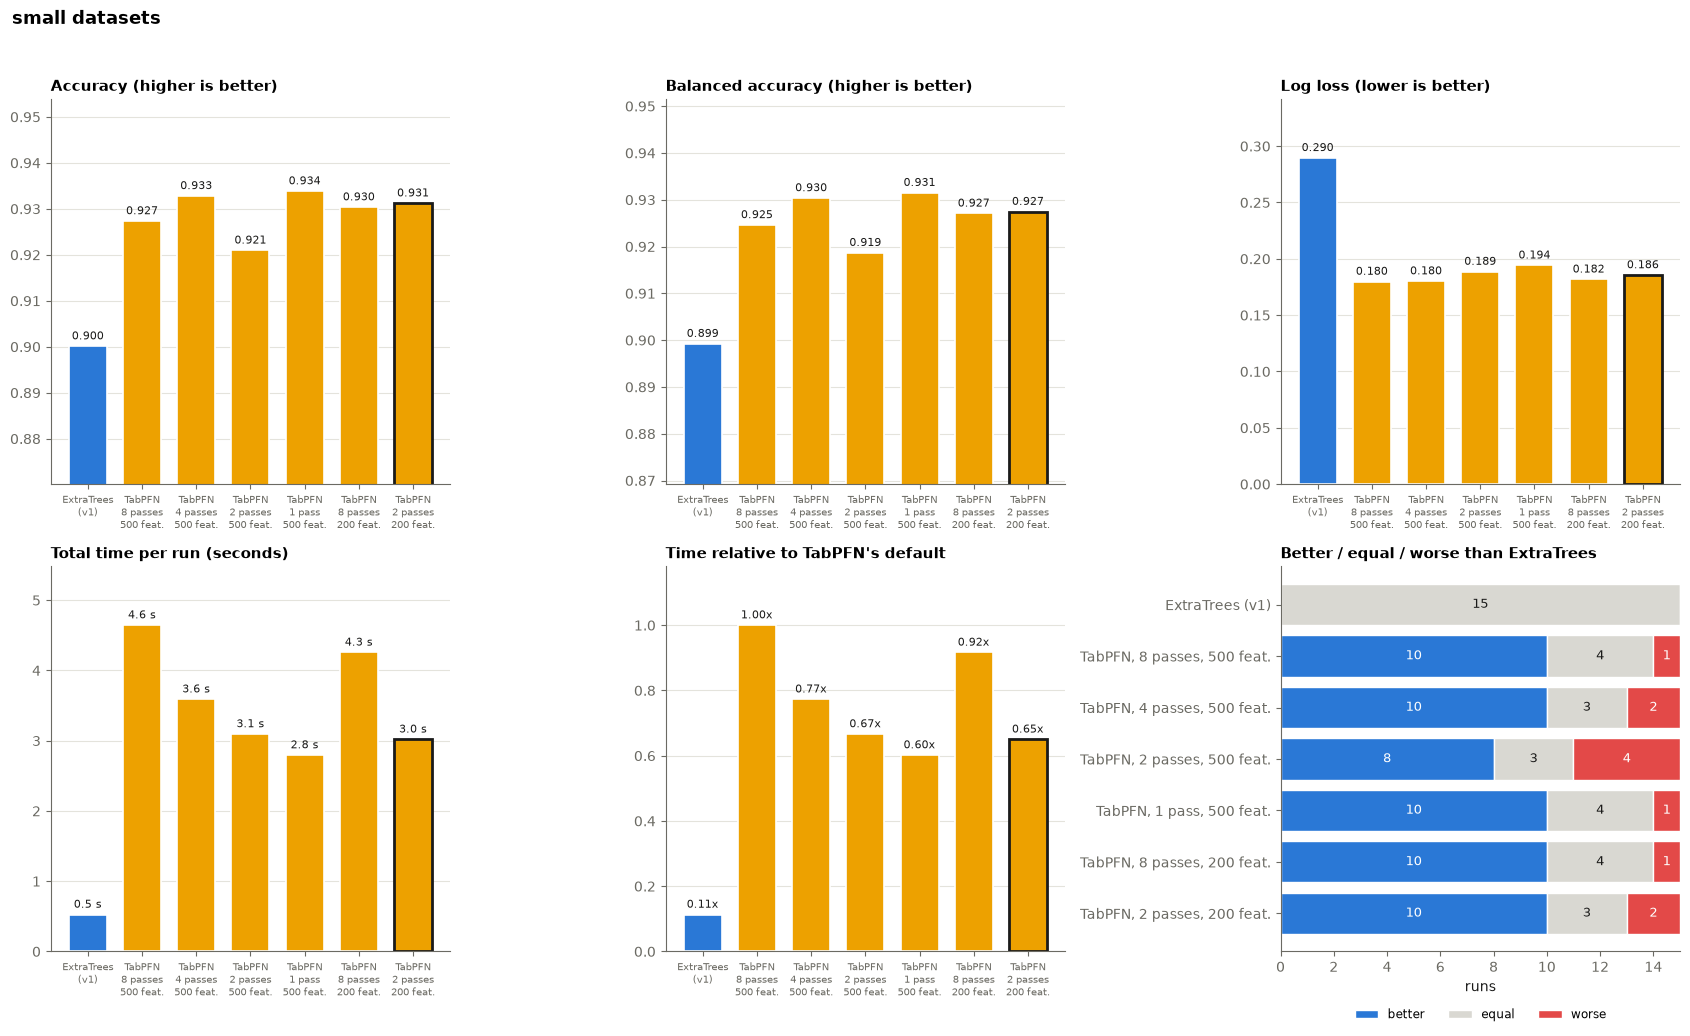

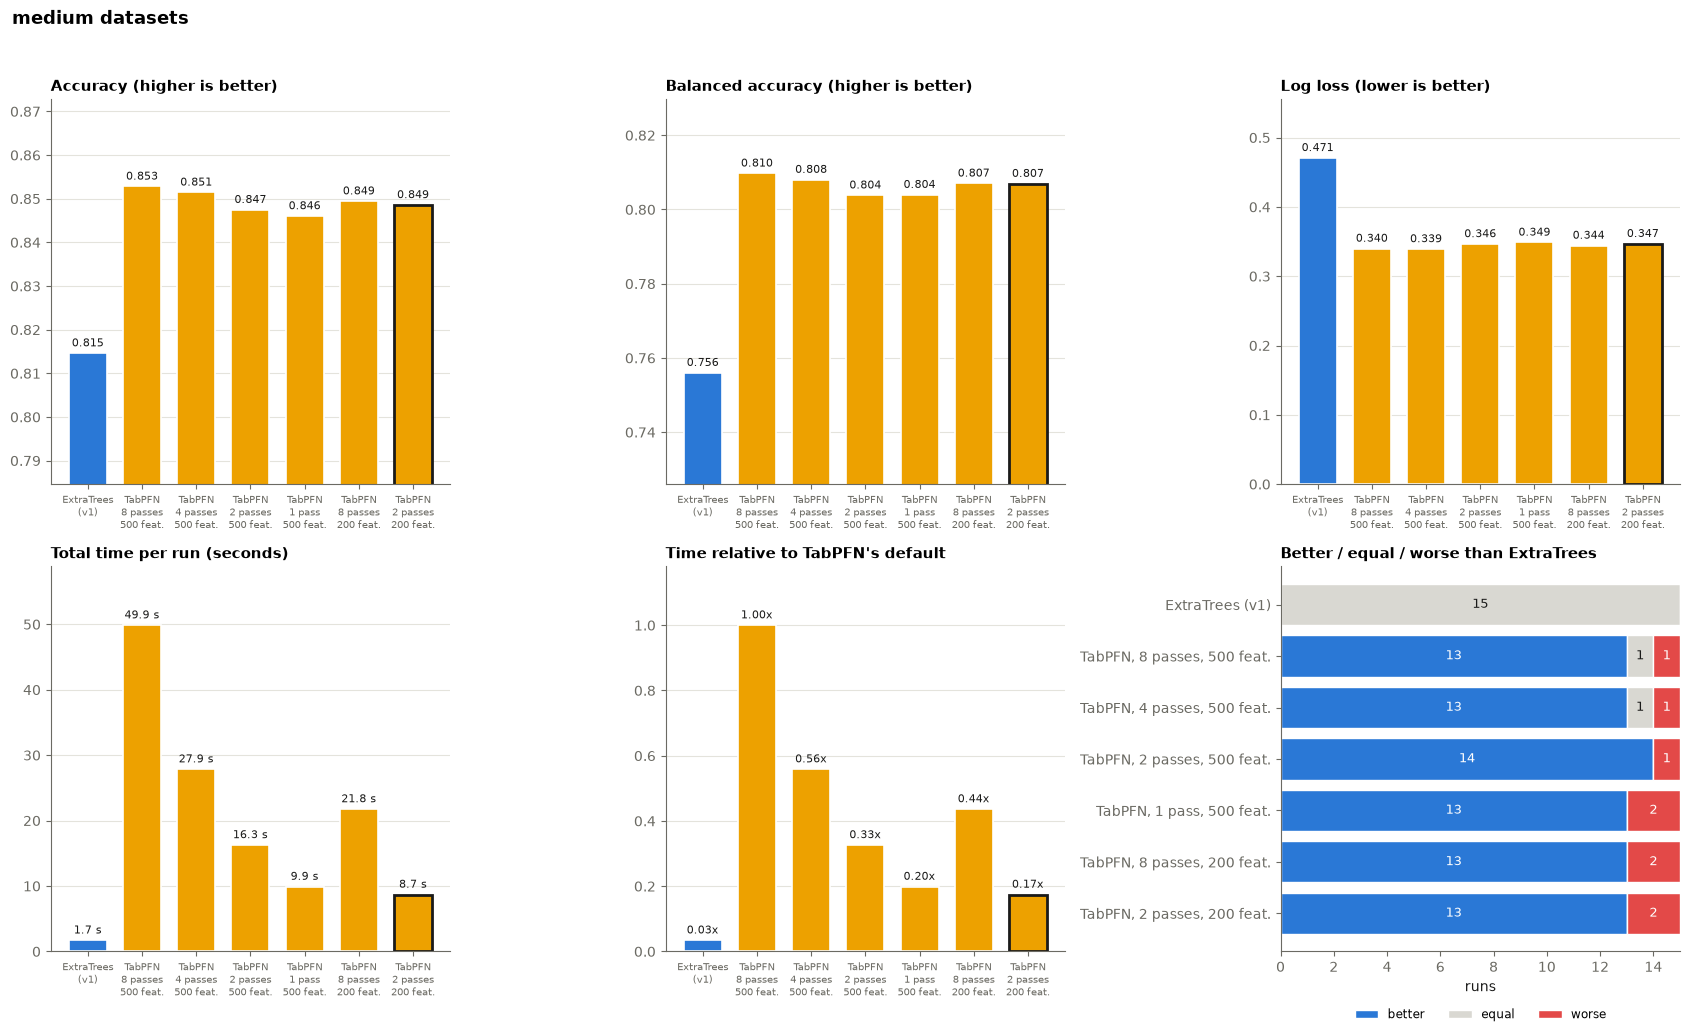

In [2]:
MAIN, PER_CONFIG = {}, {}              # per list: the configurations without a context cap, and their means
for group in GROUPS:
    runs = sweep_runs(group)
    main = MAIN[group] = ["extratrees"] + [c for c in ALL_CONFIGS if c in set(runs["classifier"]) and not c.endswith("-c1000")]
    per_config = runs[runs["classifier"].isin(main)].groupby("classifier")[
        ["accuracy", "balanced_accuracy", "log_loss", "total_time"]].mean().reindex(main)
    paired = runs.pivot_table(index=key, columns="classifier", values=["accuracy", "total_time"])   # one row per run
    per_config["time vs default"] = [paired[("total_time", c)].sum() / paired[("total_time", "tabpfn-e8f500")].sum()
                                     for c in main]
    PER_CONFIG[group] = per_config
    wdl_vs_et = [wdl_counts(paired[("accuracy", c)] - paired[("accuracy", "extratrees")]) for c in main]

    colors = [COLORS["extratrees"] if c == "extratrees" else COLORS["tabpfn"] for c in main]
    x = np.arange(len(main))
    fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
    panels = [(axes[0, 0], "accuracy", "Accuracy (higher is better)", "{:.3f}", True),
              (axes[0, 1], "balanced_accuracy", "Balanced accuracy (higher is better)", "{:.3f}", True),
              (axes[0, 2], "log_loss", "Log loss (lower is better)", "{:.3f}", False),
              (axes[1, 0], "total_time", "Total time per run (seconds)", "{:.1f} s", False),
              (axes[1, 1], "time vs default", "Time relative to TabPFN's default", "{:.2f}x", False)]
    for ax, column, title, fmt, zoomed in panels:
        bars = ax.bar(x, per_config[column], 0.7, color=colors, edgecolor="white", linewidth=1.2)
        bars[main.index("tabpfn-e2f200")].set_edgecolor(TEXT)          # a dark outline: 2 passes, 200 features
        bars[main.index("tabpfn-e2f200")].set_linewidth(2)
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=8, color=TEXT)
        ax.set_xticks(x, [config_label(c) for c in main], fontsize=7.5)
        ax.set_title(title, loc="left")
        if zoomed:                                                    # accuracy-type metrics: zoomed in on the values
            ax.set_ylim(per_config[column].min() - 0.03, min(1.0, per_config[column].max() + 0.02))
        else:
            ax.set_ylim(0, per_config[column].max() * 1.18)
    stacked_wdl(axes[1, 2], [config_label(c, lines=False) for c in main], wdl_vs_et, "Better / equal / worse than ExtraTrees")
    group_title(fig, group, top=0.96)
    plt.show()

Note: the accuracy and balanced-accuracy axes do not start at 0, to make the differences visible.

## 3. The trade-off: accuracy vs time

Each point is one configuration (mean over its 15 runs). ExtraTrees is the blue reference point. Up and to the left
is better. Time in seconds, linear axis. Left: small datasets, right: medium datasets.

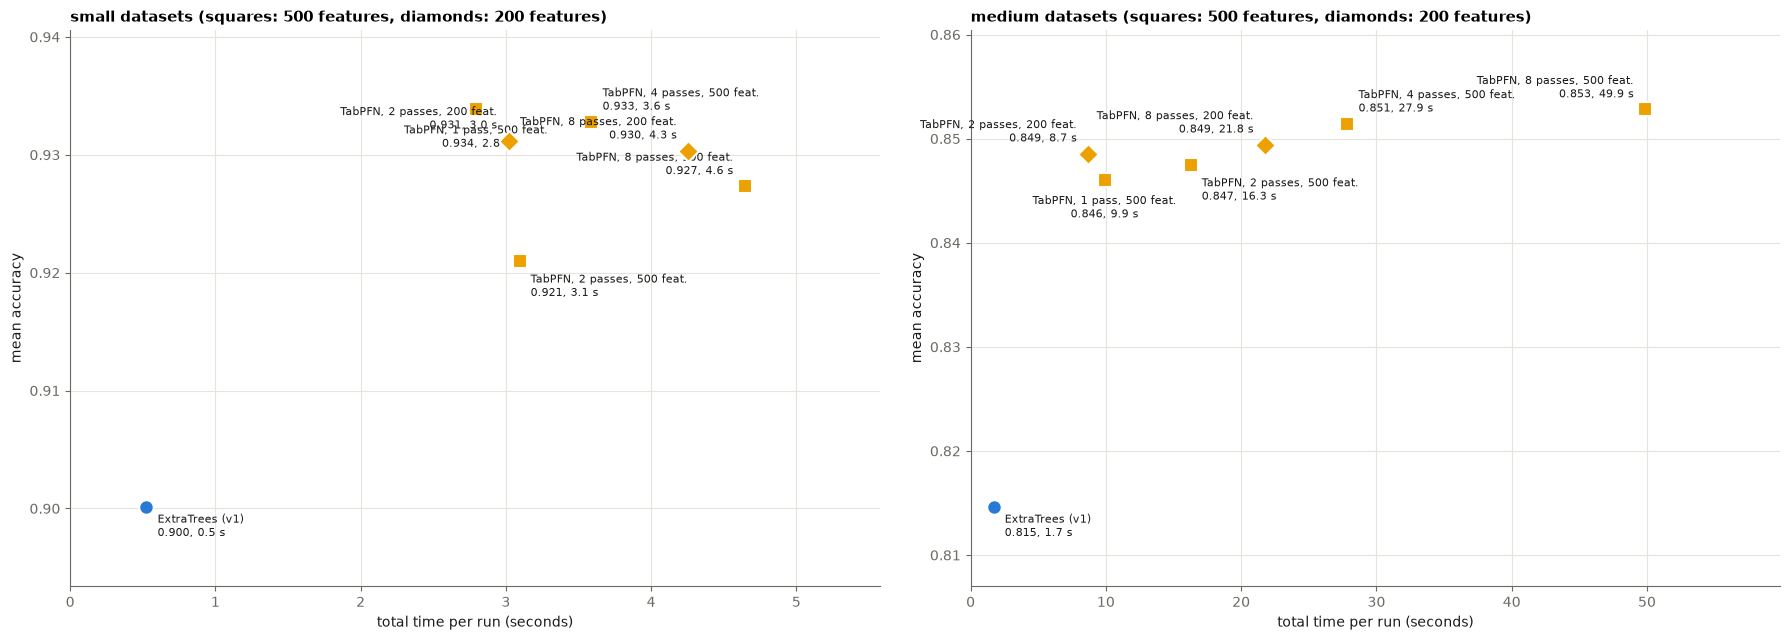

In [3]:
# where each label goes (offset in points, horizontal and vertical alignment): the TabPFN points are close together
LABEL_PLACE = {"extratrees": (8, -4, "left", "top"), "tabpfn-e8f500": (-8, 6, "right", "bottom"),
               "tabpfn-e4f500": (8, 6, "left", "bottom"), "tabpfn-e8f200": (-8, 6, "right", "bottom"),
               "tabpfn-e2f500": (8, -8, "left", "top"), "tabpfn-e2f200": (-8, 6, "right", "bottom"),
               "tabpfn-e1f500": (0, -10, "center", "top")}
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, group in zip(axes, GROUPS):
    per_config = PER_CONFIG[group]
    for c in MAIN[group]:
        row = per_config.loc[c]
        is_et = c == "extratrees"
        marker = "o" if is_et else ("s" if c.endswith("f500") else "D")   # circle: ExtraTrees, square / diamond: TabPFN
        ax.scatter(row["total_time"], row["accuracy"], s=110, marker=marker,
                   color=COLORS["extratrees"] if is_et else COLORS["tabpfn"], edgecolor="white", linewidth=1.5, zorder=3)
        dx, dy, ha, va = LABEL_PLACE.get(c, (8, -4, "left", "top"))
        ax.annotate(f"{config_label(c, lines=False)}\n{row['accuracy']:.3f}, {row['total_time']:.1f} s",
                    (row["total_time"], row["accuracy"]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8, color=TEXT, ha=ha, va=va)
    ax.set_xlim(0, per_config["total_time"].max() * 1.2)
    ax.set_xlabel("total time per run (seconds)")
    ax.set_ylabel("mean accuracy")
    ax.set_title(f"{group} datasets (squares: 500 features, diamonds: 200 features)", loc="left")
    ax.grid(True, axis="both")
    ax.margins(y=0.2)
fig.tight_layout()
plt.show()

## 4. All TabPFN versions, on both feature sets

Every TabPFN version (15 runs each per list), on two feature sets:
- **QUANT** (v1's features): the v3 sweep configurations of sections 2 and 3;
- **v2-lagd** (all QUANT features + the best lag-d features): TabPFN's default (the v2-lagd run of notebook 03),
  2 passes x 200 features (the v3-lagd tabpfn-e2f200 run) and 1 pass x 500, 400, 300, 200 or 100 features.

TabPFN always gets only its k best features (ranked by ExtraTrees importance on the training set), so the feature set
only changes which features it can choose from. Time = total time per run (feature transforms + feature selection and
ranking + fit + predict), in seconds, linear axes.

**The TabPFN version used in section 5** is the most accurate one that is at least 5 times faster than TabPFN's
default (8 passes, 500 features, QUANT's features). It is chosen on the medium datasets, where TabPFN's cost matters
(on the small datasets TabPFN's fixed start-up cost of a few seconds dominates every version), and the same version is
used for both lists; its name is printed below and it has a dark outline in the plots. The dashed line is the Pareto front: the versions that no other version beats on
both accuracy and time.

In [4]:
DEFAULT = ("QUANT", "tabpfn-e8f500")   # a TabPFN version = (feature set, configuration); the default is v1's TabPFN
TAB, VERSIONS = {}, {}                 # per list: every TabPFN run, and the means of every version
for group in GROUPS:
    runs = sweep_runs(group)
    quant = runs[runs["classifier"].str.startswith("tabpfn") & ~runs["classifier"].str.endswith("-c1000")].copy()
    quant["features"] = "QUANT"
    quant["config"] = quant["classifier"]
    frames = [quant]
    for config, d in LAGD[group].items():
        lagd = d[d["classifier"] == "tabpfn"].copy()
        lagd["features"] = "v2-lagd"
        lagd["config"] = config
        frames.append(lagd)
    tab = TAB[group] = pd.concat(frames, ignore_index=True)

    versions = tab.groupby(["features", "config"])[["accuracy", "total_time"]].mean()
    tab_paired = tab.pivot_table(index=key, columns=["features", "config"], values="accuracy")    # one row per run
    versions["wdl vs default"] = [wdl_counts(tab_paired[v] - tab_paired[DEFAULT]) for v in versions.index]
    VERSIONS[group] = versions

# the version for section 5, chosen on the medium datasets (where TabPFN's cost matters): the most accurate one that is
# at least 5 times faster than the default; the same version is used for both lists
medium = VERSIONS["medium"]
cheap = medium[medium["total_time"] <= medium.loc[DEFAULT, "total_time"] / 5]
CHOSEN = cheap.sort_values(["accuracy", "total_time"], ascending=[False, True]).index[0]
for group in GROUPS:
    v = VERSIONS[group]
    print(f"{group} datasets: {version_label(CHOSEN)}: accuracy {v.loc[CHOSEN, 'accuracy']:.3f}, "
          f"{v.loc[CHOSEN, 'total_time']:.1f} s per run ({v.loc[DEFAULT, 'total_time'] / v.loc[CHOSEN, 'total_time']:.1f}x "
          f"faster than the default, accuracy {signed(v.loc[CHOSEN, 'accuracy'] - v.loc[DEFAULT, 'accuracy'])})")

small datasets: TabPFN, 1 pass, 300 feat. (v2-lagd): accuracy 0.932, 3.1 s per run (1.5x faster than the default, accuracy +0.005)
medium datasets: TabPFN, 1 pass, 300 feat. (v2-lagd): accuracy 0.849, 7.7 s per run (6.5x faster than the default, accuracy -0.003)


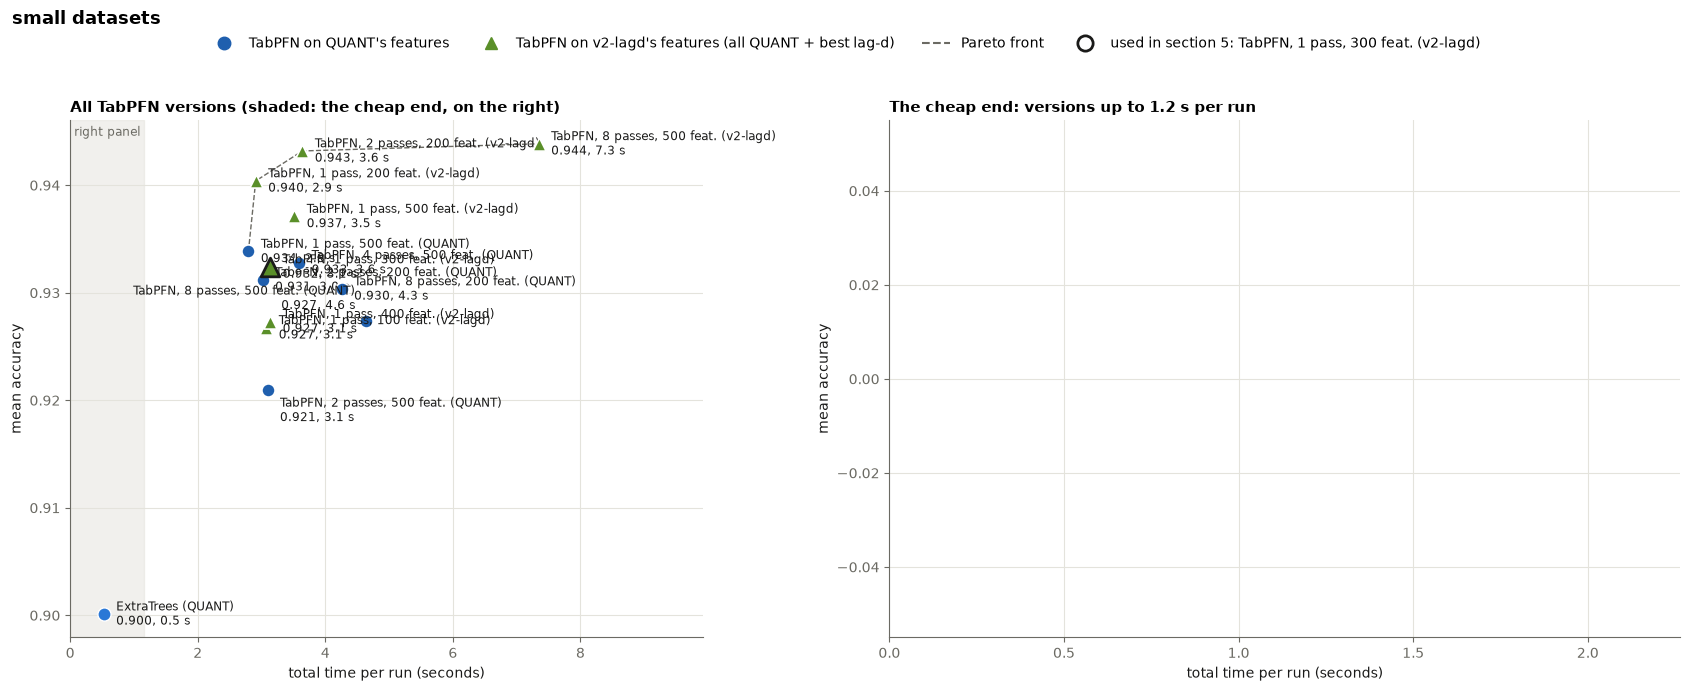

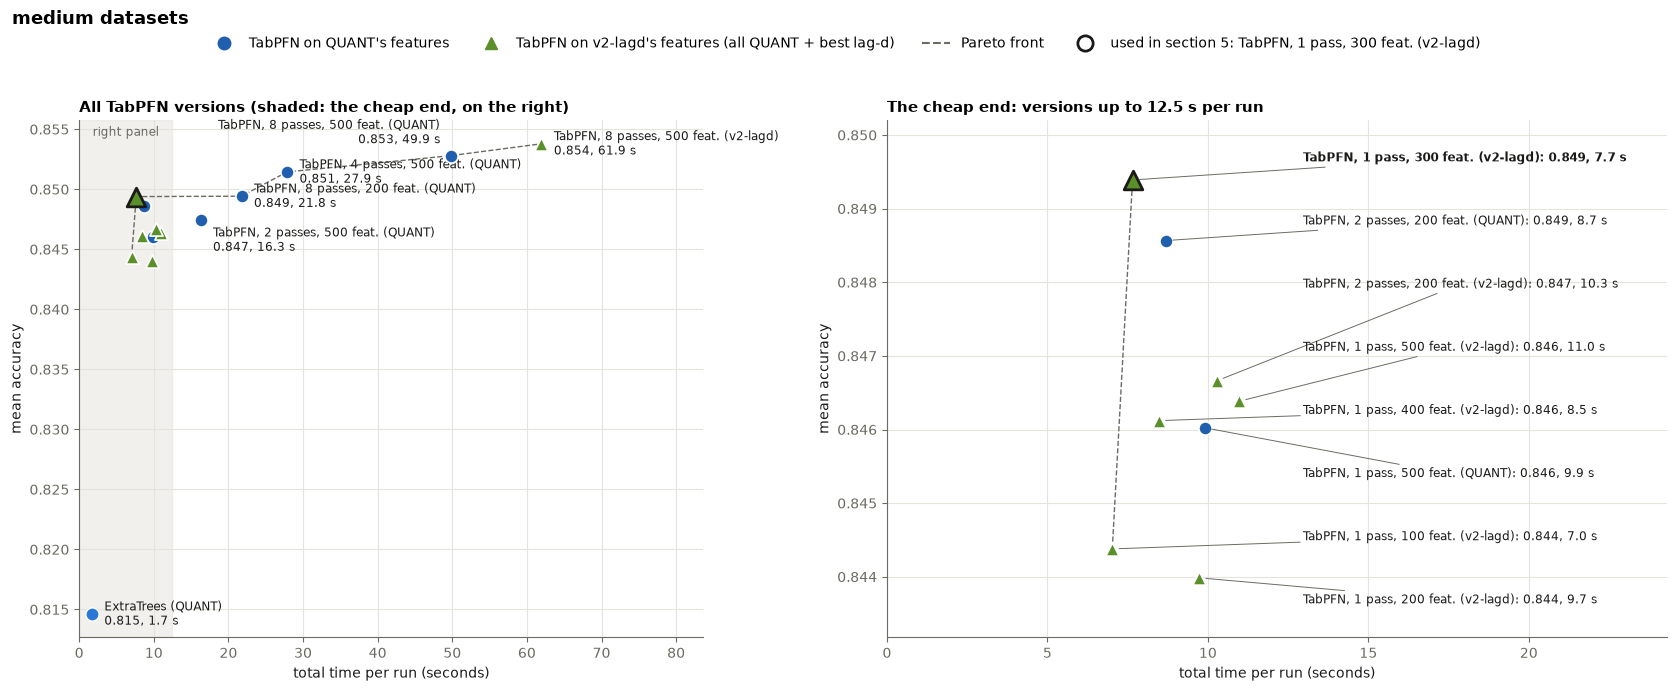

In [5]:
MARKERS_F = {"QUANT": "o", "v2-lagd": "^"}
# label placement (offset in points, alignment) where the default would overlap
PLACE = {("QUANT", "tabpfn-e8f500"): (-8, 6, "right", "bottom"), ("v2-lagd", "tabpfn-e8f500"): (9, 0, "left", "center"),
         ("QUANT", "tabpfn-e2f500"): (9, -4, "left", "top")}
for group in GROUPS:
    versions = VERSIONS[group]
    zoom = versions.loc[DEFAULT, "total_time"] / 4             # the right panel: the versions up to this time
    # the Pareto front: going from the fastest to the slowest version, every version more accurate than all faster ones
    front, top = [], -1.0
    for v, row in versions.sort_values("total_time").iterrows():
        if row["accuracy"] > top:
            front.append(v)
            top = row["accuracy"]
    et = PER_CONFIG[group].loc["extratrees"]
    fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1, 1.25]})
    for ax, shown in [(axes[0], versions), (axes[1], versions[versions["total_time"] <= zoom])]:
        on_front = [v for v in front if v in shown.index]
        ax.plot(versions.loc[on_front, "total_time"], versions.loc[on_front, "accuracy"], color=MUTED, linestyle="--",
                linewidth=1, zorder=1)
        for v, row in shown.iterrows():
            ax.scatter(row["total_time"], row["accuracy"], s=180 if v == CHOSEN else 90, marker=MARKERS_F[v[0]],
                       color=FEATURE_COLORS[v[0]], edgecolor=TEXT if v == CHOSEN else "white",
                       linewidth=2 if v == CHOSEN else 1.2, zorder=3)
            if row["total_time"] <= zoom:                     # the cheap versions: labelled in the right panel
                continue
            dx, dy, ha, va = PLACE.get(v, (9, 0, "left", "center"))
            ax.annotate(f"{version_label(v)}\n{row['accuracy']:.3f}, {row['total_time']:.1f} s",
                        (row["total_time"], row["accuracy"]), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                        fontsize=8.5, color=TEXT)
        ax.set_xlabel("total time per run (seconds)")
        ax.set_ylabel("mean accuracy")
        ax.grid(True, axis="both")
    axes[0].scatter(et["total_time"], et["accuracy"], s=90, color=COLORS["extratrees"], edgecolor="white", zorder=3)
    axes[0].annotate(f"ExtraTrees (QUANT)\n{et['accuracy']:.3f}, {et['total_time']:.1f} s",
                     (et["total_time"], et["accuracy"]), xytext=(9, 0), textcoords="offset points", va="center",
                     fontsize=8.5, color=TEXT)
    axes[0].axvspan(0, zoom, color=GRID, alpha=0.5, zorder=0)
    axes[0].annotate("right panel", (zoom / 2, axes[0].get_ylim()[1]), xytext=(0, -4), textcoords="offset points",
                     ha="center", va="top", fontsize=8.5, color=MUTED)
    axes[0].set_xlim(0, versions["total_time"].max() * 1.35)
    axes[0].set_title("All TabPFN versions (shaded: the cheap end, on the right)", loc="left")
    # the cheap versions are close together: their labels go in a column on the right, sorted by accuracy,
    # with a thin line to each point
    cheap_end = versions[versions["total_time"] <= zoom].sort_values("accuracy", ascending=False)
    label_y = np.linspace(cheap_end["accuracy"].max() + 0.0003, cheap_end["accuracy"].min() - 0.0003, len(cheap_end))
    for (v, row), yy in zip(cheap_end.iterrows(), label_y):
        axes[1].annotate(f"{version_label(v)}: {row['accuracy']:.3f}, {row['total_time']:.1f} s",
                         (row["total_time"], row["accuracy"]), xytext=(zoom * 1.04, yy), textcoords="data",
                         va="center", fontsize=8.5, color=TEXT, fontweight="bold" if v == CHOSEN else "normal",
                         arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.7, shrinkA=0, shrinkB=5))
    axes[1].set_xlim(0, zoom * 1.95)
    axes[1].margins(y=0.15)
    axes[1].set_title(f"The cheap end: versions up to {zoom:.1f} s per run", loc="left")
    # the legend: the two markers, the Pareto front and the outlined chosen version
    handles = [plt.Line2D([], [], marker=MARKERS_F[f], linestyle="", color=FEATURE_COLORS[f], markersize=9) for f in MARKERS_F]
    handles += [plt.Line2D([], [], color=MUTED, linestyle="--"),
                plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=TEXT,
                           markeredgewidth=2, markersize=11)]
    fig.legend(handles, ["TabPFN on QUANT's features", "TabPFN on v2-lagd's features (all QUANT + best lag-d)",
                         "Pareto front", f"used in section 5: {version_label(CHOSEN)}"],
               loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.96))
    group_title(fig, group, top=0.92)
    plt.show()

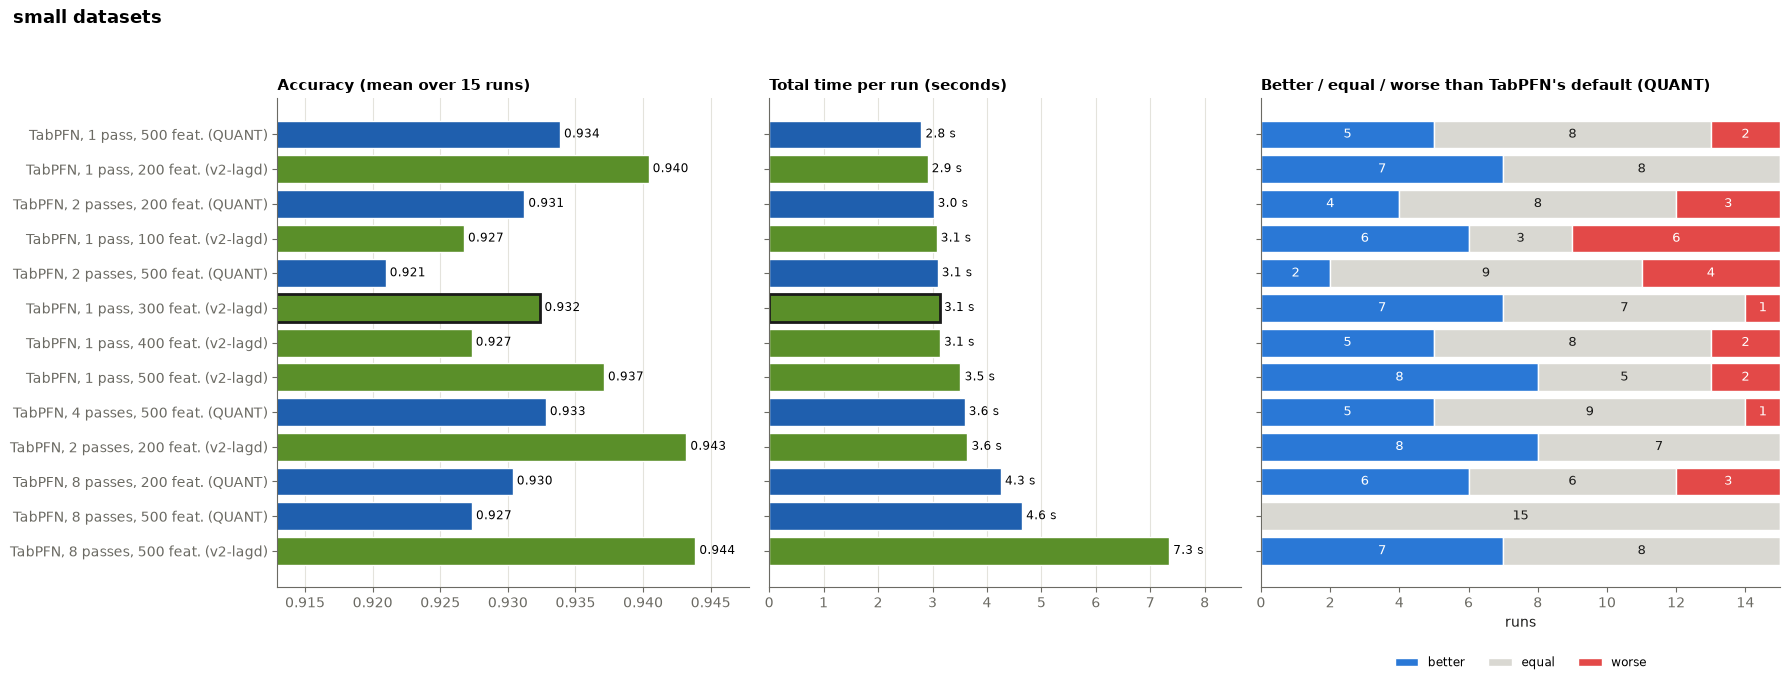

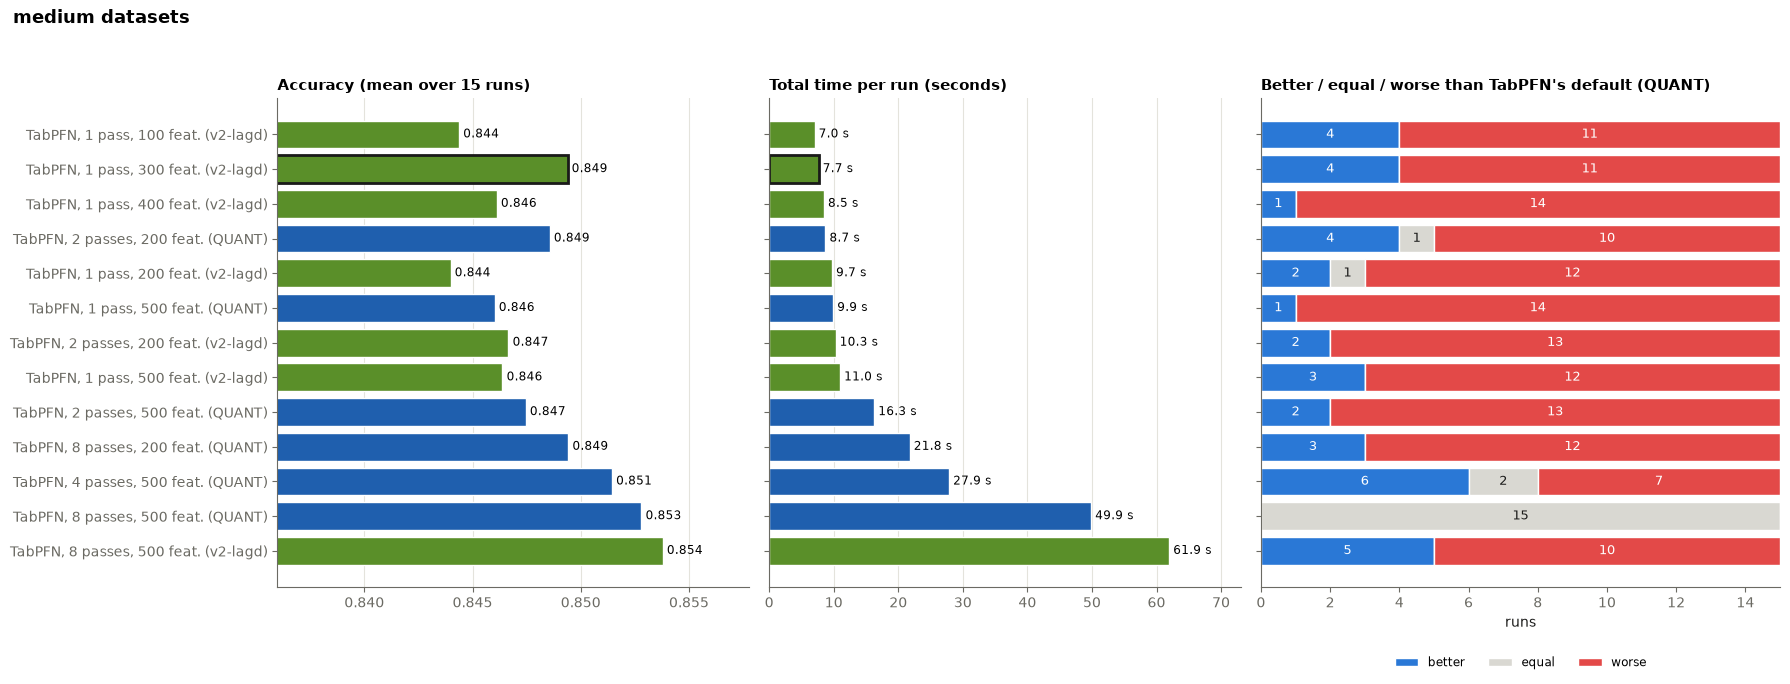

In [6]:
# every version: accuracy, time, and better / equal / worse than TabPFN's default (fastest at the top)
for group in GROUPS:
    versions = VERSIONS[group]
    order = versions.sort_values("total_time").index.tolist()
    y = np.arange(len(order))[::-1]
    colors = [FEATURE_COLORS[v[0]] for v in order]
    edges = [TEXT if v == CHOSEN else "white" for v in order]          # the chosen version: a dark outline
    widths = [2 if v == CHOSEN else 1 for v in order]
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    for ax, column, fmt, title in [(axes[0], "accuracy", "{:.3f}", "Accuracy (mean over 15 runs)"),
                                   (axes[1], "total_time", "{:.1f} s", "Total time per run (seconds)")]:
        bars = ax.barh(y, versions.loc[order, column], color=colors, edgecolor=edges, linewidth=widths)
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=8.5)
        ax.set_yticks(y, [version_label(v) for v in order] if ax is axes[0] else [])
        ax.set_title(title, loc="left")
        ax.grid(True, axis="x")
        ax.grid(False, axis="y")
    axes[0].set_xlim(versions["accuracy"].min() - 0.008, versions["accuracy"].max() + 0.004)
    axes[0].xaxis.set_major_locator(plt.MultipleLocator(0.005))
    axes[1].set_xlim(0, versions["total_time"].max() * 1.18)
    stacked_wdl(axes[2], [""] * len(order), [versions.loc[v, "wdl vs default"] for v in order],
                "Better / equal / worse than TabPFN's default (QUANT)")
    group_title(fig, group)
    plt.show()

Note: the accuracy axis does not start at 0, to make the differences visible; the time axis starts at 0.

## 5. The chosen TabPFN vs v1

The TabPFN version picked in section 4 against the two v1 references, on the same 15 runs (5 datasets x 3 resamples):
- **QUANT + ExtraTrees (v1)**: the original QUANT method;
- **QUANT + TabPFN default (v1)**: TabPFN with 8 passes and 500 features on QUANT's features;
- **the chosen TabPFN** (its name is in the plots), dark outline.

Top: accuracy, with the chosen TabPFN's change against each reference; bottom: total time per run (transforms +
feature selection and ranking + fit + predict), in seconds. The runs come from different sessions, so small time
differences are not meaningful (TabPFN's default took 49.9 s per run on the medium datasets in the v3 sweep
run, 52.2 s in the v1 run, for identical results).

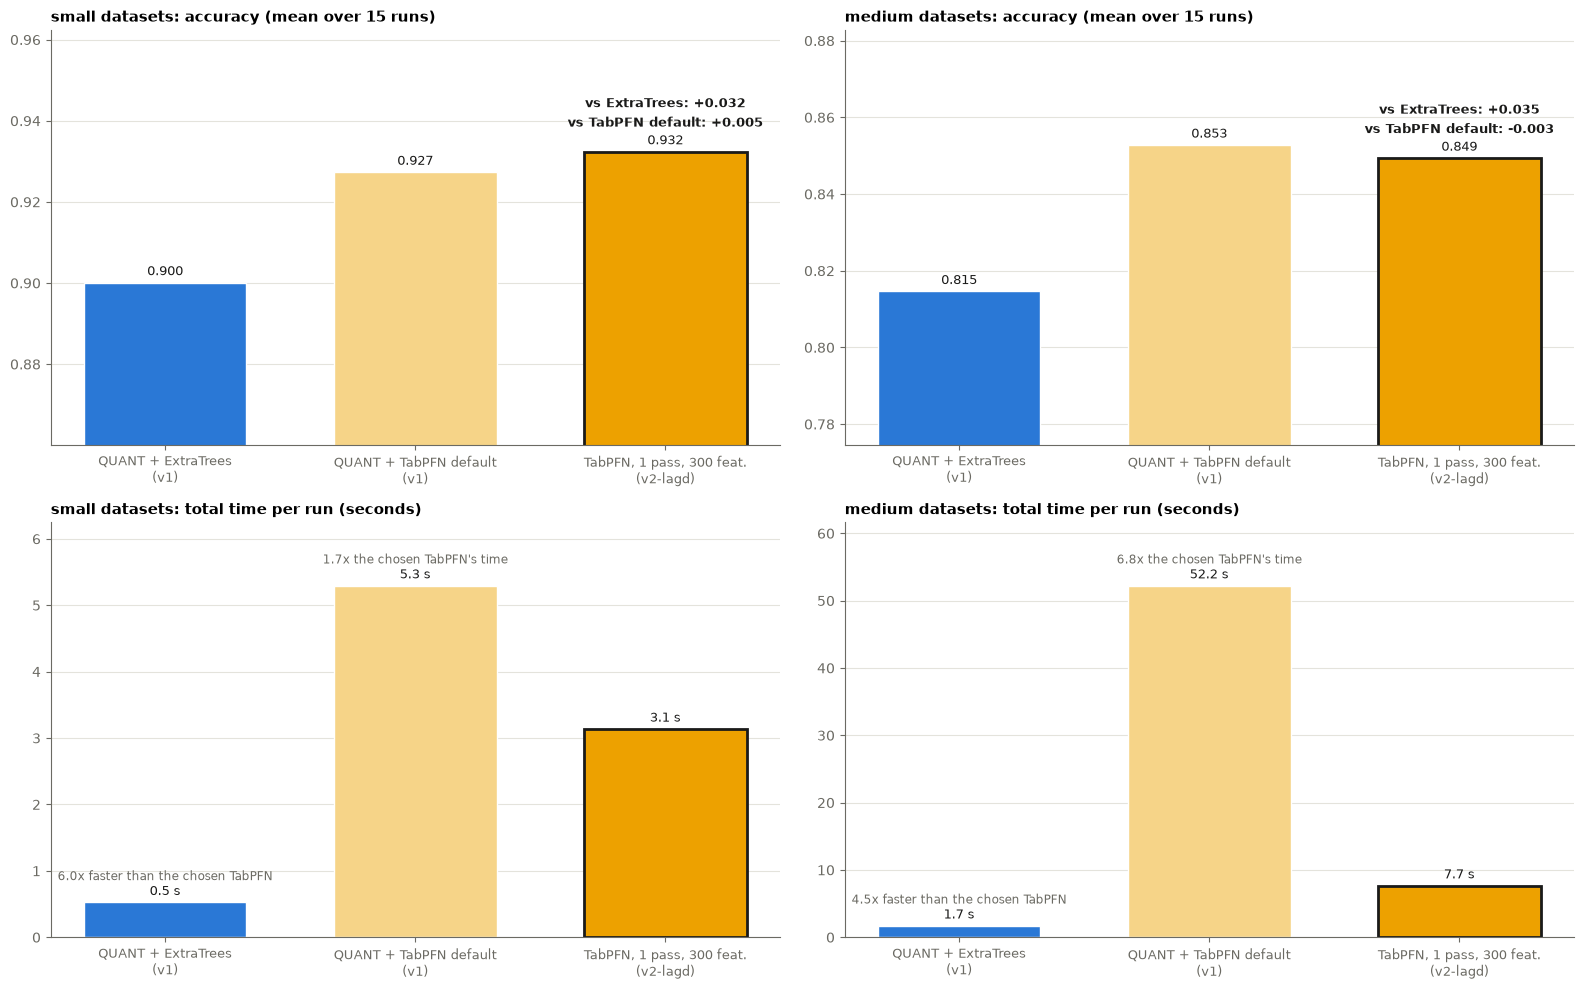

In [7]:
REF_ET, REF_TAB = "QUANT + ExtraTrees (v1)", "QUANT + TabPFN default (v1)"
CHOSEN_NAME = version_label(CHOSEN)
ENTRIES = [REF_ET, REF_TAB, CHOSEN_NAME]
ENTRY_COLORS = {REF_ET: COLORS["extratrees"], REF_TAB: "#f6d488", CHOSEN_NAME: COLORS["tabpfn"]}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for col, group in enumerate(GROUPS):
    v1, tab = V1[group], TAB[group]
    entries = {REF_ET: v1[v1["classifier"] == "extratrees"],                 # the same 15 runs for all three
               REF_TAB: v1[v1["classifier"] == "tabpfn"],
               CHOSEN_NAME: tab[(tab["features"] == CHOSEN[0]) & (tab["config"] == CHOSEN[1])]}
    for row, (metric, title, fmt) in enumerate([("accuracy", "accuracy (mean over 15 runs)", "{:.3f}"),
                                                ("total_time", "total time per run (seconds)", "{:.1f} s")]):
        ax = axes[row, col]
        values = [entries[name][metric].mean() for name in ENTRIES]
        bars = ax.bar(range(3), values, 0.65, color=[ENTRY_COLORS[n] for n in ENTRIES],
                      edgecolor=["white", "white", TEXT], linewidth=[1, 1, 2])
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9.5, color=TEXT)
        ax.set_xticks(range(3), [n.replace(" (", "\n(") for n in ENTRIES], fontsize=9)
        ax.set_title(f"{group} datasets: {title}", loc="left")
        if metric == "accuracy":
            ax.set_ylim(min(values) - 0.04, min(1.0, max(values) + 0.03))
            for k, ref in enumerate([REF_ET, REF_TAB]):        # the chosen TabPFN's change against each reference
                ax.annotate(f"vs {'ExtraTrees' if ref == REF_ET else 'TabPFN default'}: "
                            f"{signed(values[2] - values[k])}", (2, values[2]), xytext=(0, 18 + 14 * (1 - k)),
                            textcoords="offset points", ha="center", fontsize=9, color=TEXT, fontweight="bold")
        else:
            ax.set_ylim(0, max(values) * 1.18)
            for k in range(2):                                 # each reference's time against the chosen TabPFN's
                ax.annotate(f"{values[k] / values[2]:.1f}x the chosen TabPFN's time" if values[k] > values[2]
                            else f"{values[2] / values[k]:.1f}x faster than the chosen TabPFN",
                            (k, values[k]), xytext=(0, 16), textcoords="offset points", ha="center", fontsize=8.5,
                            color=MUTED)
fig.tight_layout()
plt.show()

Note: the accuracy axes do not start at 0, to make the differences visible; the time axes start at 0.

## 6. The training-context cap (medium datasets: the two with more than 1,000 training cases)

At most 1,000 training cases (stratified random subset) instead of all of them, for 8 and for 2 passes (500 features),
on PhalangesOutlinesCorrect and AconityMINIPrinterLargeEq (6 runs each). The small datasets have at most 100 training
cases, so the cap does not apply to them.

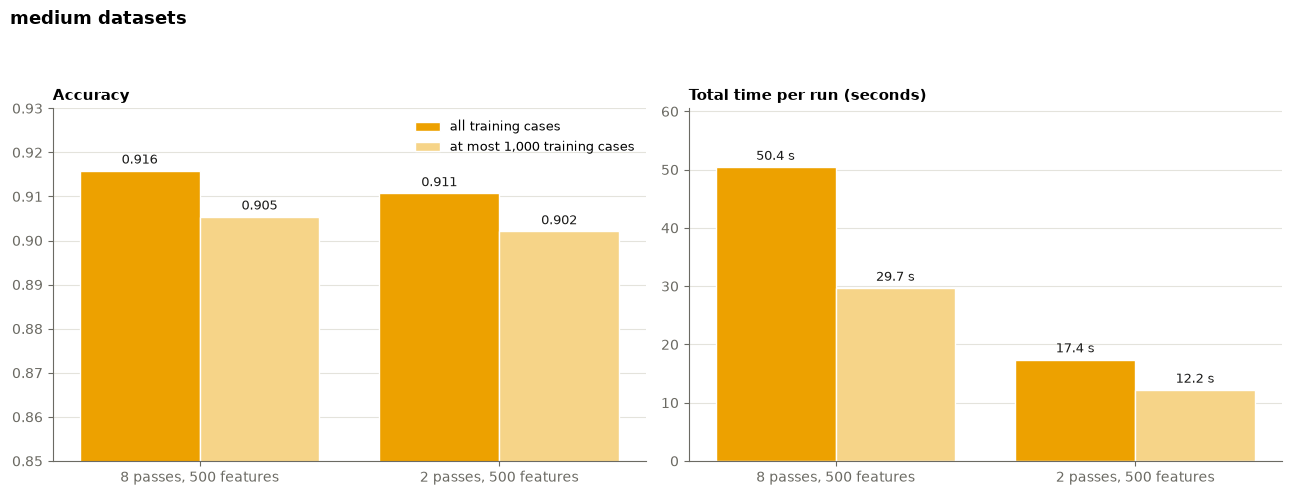

In [8]:
cap_sets = ["PhalangesOutlinesCorrect", "AconityMINIPrinterLargeEq"]       # the medium datasets with > 1,000 training cases
medium_runs = sweep_runs("medium")
cap = medium_runs[medium_runs["dataset"].isin(cap_sets)].groupby("classifier")[["accuracy", "total_time"]].mean()
pairs = [("tabpfn-e8f500", "tabpfn-e8f500-c1000"), ("tabpfn-e2f500", "tabpfn-e2f500-c1000")]     # without / with the cap
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, column, title, fmt in [(axes[0], "accuracy", "Accuracy", "{:.3f}"),
                               (axes[1], "total_time", "Total time per run (seconds)", "{:.1f} s")]:
    for k, (without, with_cap) in enumerate(pairs):
        for offset, c, color, label in [(-0.2, without, COLORS["tabpfn"], "all training cases"),
                                        (0.2, with_cap, "#f6d488", "at most 1,000 training cases")]:
            bars = ax.bar(k + offset, cap.loc[c, column], 0.4, color=color, edgecolor="white",
                          label=label if k == 0 else None)            # each label once in the legend
            ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9, color=TEXT)
    ax.set_xticks([0, 1], ["8 passes, 500 features", "2 passes, 500 features"])
    ax.set_title(title, loc="left")
axes[0].set_ylim(0.85, 0.93)
axes[1].set_ylim(0, cap["total_time"].max() * 1.2)
axes[0].legend(loc="upper right", frameon=False, fontsize=9)
group_title(fig, "medium", top=0.92)
plt.show()

Note: the accuracy axis starts at 0.85 to make the differences visible.

## 7. Building TabPFN's model once (the model cache)

Every new TabPFN classifier rebuilds TabPFN's model (an 876 MB file of weights) and copies it to the GPU, about 2
to 3 s for every run, even on a dataset with 30 training cases. TabPFN has its own cache for this
(`TABPFN_MODEL_CACHE_SIZE=1`): the model is built once per process and reused. `improvedQuant/features/run.py`
switches it on with `--tabpfn_cache`; it is off by default, so all the other runs (sections 2 to 6, and notebooks
02 and 03) build the model for every run.

The test: three configurations of the sweep on QUANT's features (8 passes x 500 features = the default, 2 x 200,
1 x 500) and the chosen version (1 pass x 300 features on v2-lagd), run again with the cache on the same 15 runs per
list, against the same configurations without it.

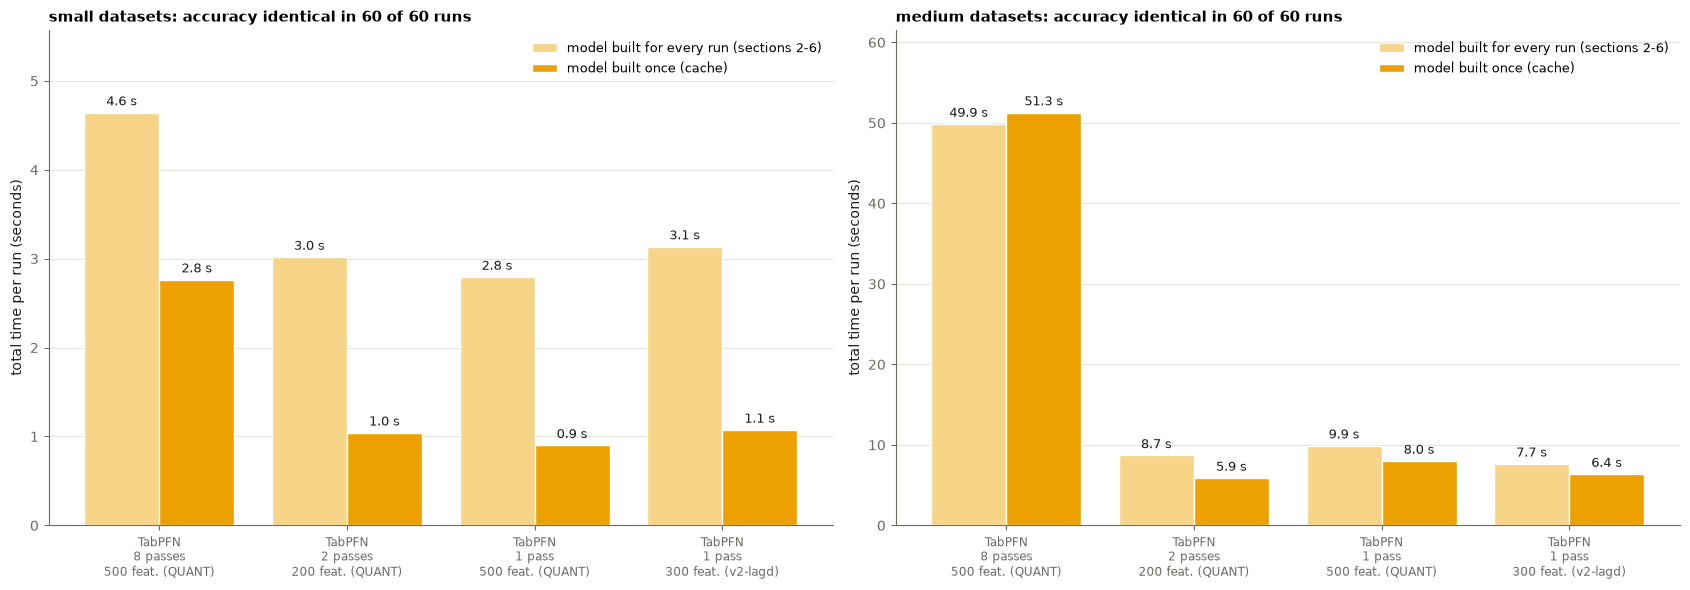

In [9]:
# (feature set, configuration): three sweep configurations on QUANT's features and the chosen version on v2-lagd's
CACHED = [("QUANT", "tabpfn-e8f500"), ("QUANT", "tabpfn-e2f200"), ("QUANT", "tabpfn-e1f500"), ("v2-lagd", "tabpfn-e1f300")]
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, group in zip(axes, GROUPS):
    means, identical, total = [], 0, 0
    for features, config in CACHED:
        if features == "QUANT":
            without = SWEEP[group][SWEEP[group]["classifier"] == config]
            cached = load(sweep_file(config, group, "-cache").name)
        else:
            without = LAGD[group][config]
            cached = load(f"v3-lagd_{config}-cache_smoke-{group}_allcores-gpu.csv")
        both = without.merge(cached, on=key, suffixes=("", " cached"))   # the same runs without / with the cache
        identical += (both["accuracy"] == both["accuracy cached"]).sum()
        total += len(both)
        means.append((both["total_time"].mean(), both["total_time cached"].mean()))
    x = np.arange(len(CACHED))
    for k, (offset, color, label) in enumerate([(-0.2, "#f6d488", "model built for every run (sections 2-6)"),
                                                (0.2, COLORS["tabpfn"], "model built once (cache)")]):
        bars = ax.bar(x + offset, [m[k] for m in means], 0.4, color=color, edgecolor="white", label=label)
        ax.bar_label(bars, fmt="{:.1f} s", padding=3, fontsize=9, color=TEXT)
    ax.set_xticks(x, [version_label(v).replace(", ", "\n") for v in CACHED], fontsize=8.5)
    ax.set_ylim(0, max(max(m) for m in means) * 1.2)
    ax.set_ylabel("total time per run (seconds)")
    ax.set_title(f"{group} datasets: accuracy identical in {identical} of {total} runs", loc="left")
    ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

Note: the two runs of each configuration come from different sessions, so differences of a second or two on the
slow default (8 passes, medium datasets) are noise.

## 8. A feature extractor for TabPFN (`quant_tabpfn.py`)

QUANT's features are made for trees: many near-copies (neighbouring quantiles, half-overlapping pieces) and every
second quantile minus the piece's average. With a budget of 200 or 300 features, near-copies waste TabPFN's slots.
`improvedQuant/features/quant_tabpfn.py` (`--quant tabpfn`) is a changed copy of QUANT: 5 levels of pieces instead
of 6, one quantile per 8 points instead of 4, no shifted pieces, no average subtraction, and per piece also its
mean, spread and trend. The lag-d differences of v2-lagd use the same extractor.

The test: the two cheap settings (1 pass x 300 features, 2 passes x 200) on the v2-lagd features, with the model
cache, once with QUANT's original extractor (v3-lagd) and once with the new one (v4-first), on the same 15 runs per list.

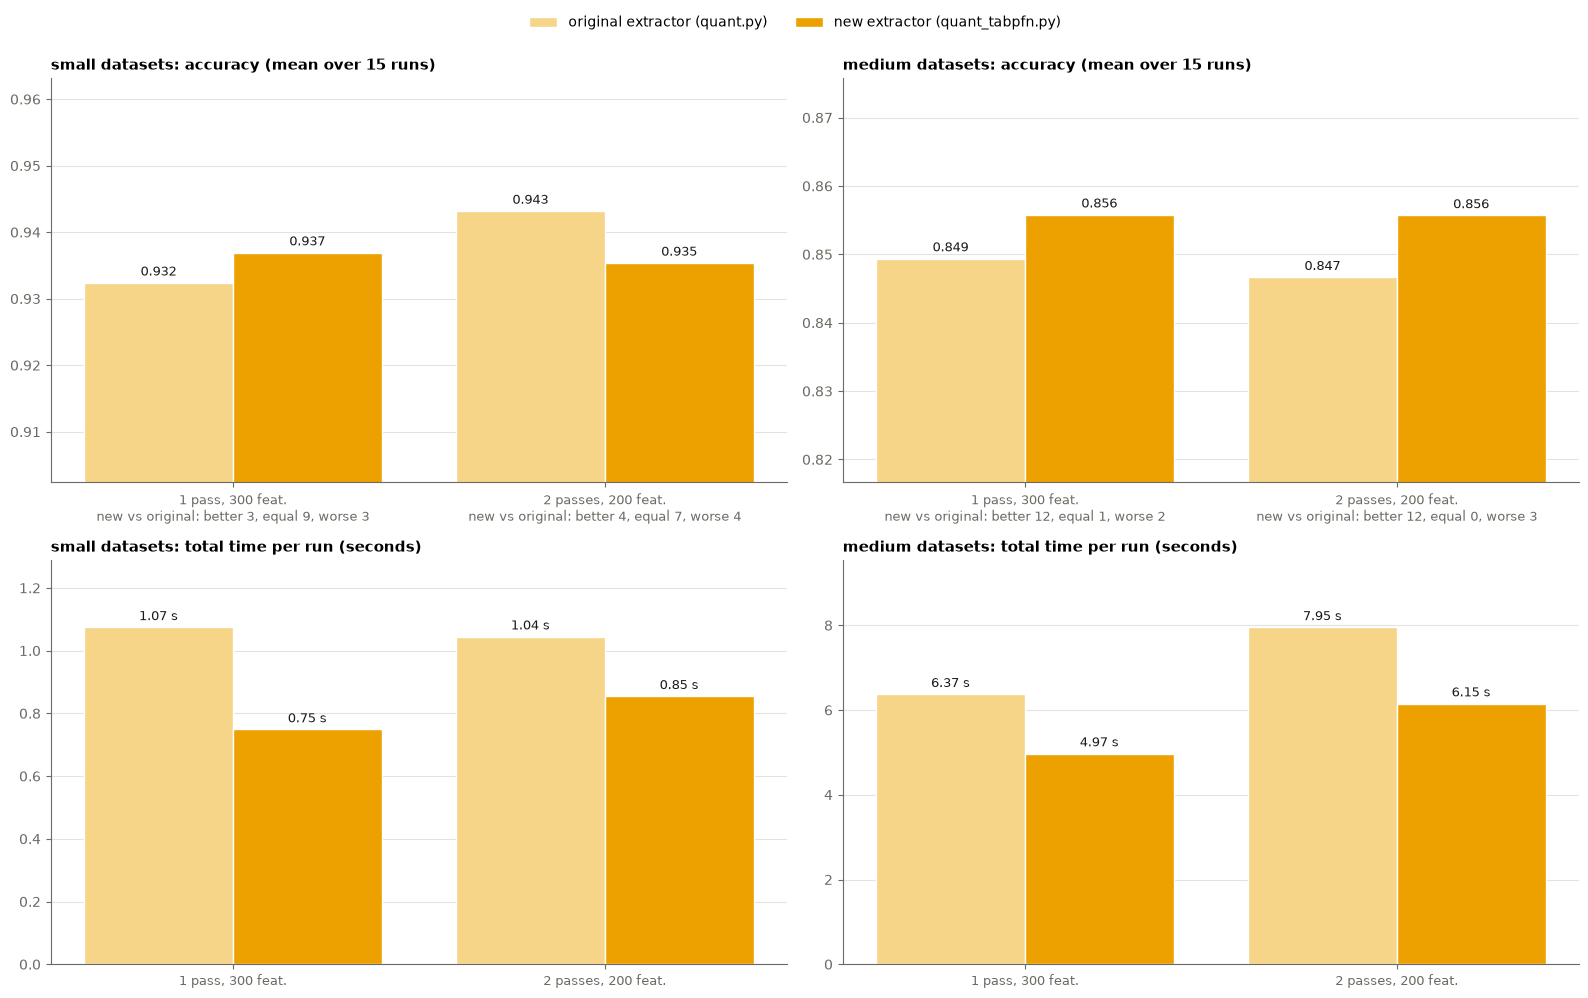

In [10]:
EXTRACTOR_CONFIGS = ["tabpfn-e1f300", "tabpfn-e2f200"]
EXTRACTORS = {"original extractor (quant.py)": False, "new extractor (quant_tabpfn.py)": True}
EXTRACTOR_COLORS = ["#f6d488", COLORS["tabpfn"]]

def lagd_cached(config, group, new):
    """A TabPFN run on v2-lagd's settings with the model cache: QUANT's original extractor (new=False: v3-lagd) or the
    first version of the new one (new=True: v4-first)."""
    return load(f"{'v4-first' if new else 'v3-lagd'}_{config}-cache_smoke-{group}_allcores-gpu.csv")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for col, group in enumerate(GROUPS):
    stats = []                          # per setting: the means of both extractors, and new vs original per run
    for config in EXTRACTOR_CONFIGS:
        both = lagd_cached(config, group, False).merge(lagd_cached(config, group, True), on=key, suffixes=("", " new"))
        stats.append({"accuracy": (both["accuracy"].mean(), both["accuracy new"].mean()),
                      "total_time": (both["total_time"].mean(), both["total_time new"].mean()),
                      "wdl": wdl_counts(both["accuracy new"] - both["accuracy"])})
    x = np.arange(len(EXTRACTOR_CONFIGS))
    for row, (metric, title, fmt) in enumerate([("accuracy", "accuracy (mean over 15 runs)", "{:.3f}"),
                                                ("total_time", "total time per run (seconds)", "{:.2f} s")]):
        ax = axes[row, col]
        for k, (label, color) in enumerate(zip(EXTRACTORS, EXTRACTOR_COLORS)):
            bars = ax.bar(x + (k - 0.5) * 0.4, [s[metric][k] for s in stats], 0.4, color=color, edgecolor="white",
                          label=label)
            ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9, color=TEXT)
        values = [v for s in stats for v in s[metric]]
        names = [config_label(c, lines=False).replace("TabPFN, ", "") for c in EXTRACTOR_CONFIGS]
        if metric == "accuracy":        # under each setting: in how many runs the new extractor is better / equal / worse
            names = [f"{n}\nnew vs original: better {w[0]}, equal {w[1]}, worse {w[2]}"
                     for n, w in zip(names, [s["wdl"] for s in stats])]
            ax.set_ylim(min(values) - 0.03, min(1.0, max(values) + 0.02))
        else:
            ax.set_ylim(0, max(values) * 1.2)
        ax.set_xticks(x, names, fontsize=9)
        ax.set_title(f"{group} datasets: {title}", loc="left")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

Note: the accuracy axes do not start at 0, to make the differences visible; the time axes start at 0.

## 9. Which features are produced, kept and chosen

The runs with 1 pass x 300 features of section 8 (v3-lagd with QUANT's original extractor, v4-first with the new one) and
of section 10 (v4: the new extractor with 4 levels and 2 quantiles per piece, lag-d 4 and 16, ExtraTrees ranking)
also wrote `..._features.csv` (`--feature_log`): for every dataset and resample, how many features of each class are
1. **produced**: QUANT's four views of the series (the series itself, its change, the change of the change, its
   rhythm = |FFT|) and the lag-d differences (d = 2, 4, 8, 16; v4: 4 and 16);
2. **kept by the filter**: every QUANT feature and the best lag-d ones (as many as QUANT has; in v4 all of them);
3. **given to TabPFN**: the 300 most important ones, ranked by ExtraTrees on the training data (TabPFN itself does
   not choose: it uses all 300).

Every plot shows the mean over the datasets and resamples of a list (15 runs).

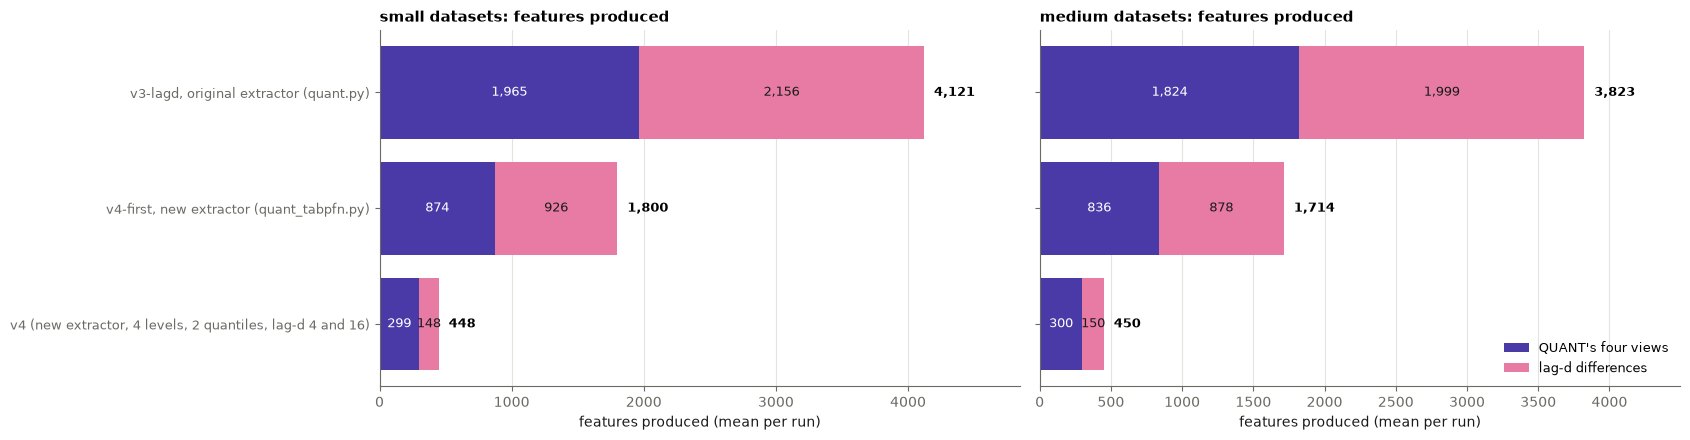

In [11]:
SOURCES = ["series", "change (smoothed)", "change of change", "rhythm (|FFT|)", "lag-2", "lag-4", "lag-8", "lag-16"]
SOURCE_COLORS = dict(zip(SOURCES, ["#2e2380", "#4a3aa7", "#7a6dd0", "#b3abeb", "#9c2f5c", "#c94f80", "#e87ba4", "#f6c3d6"]))
STEPS = {"1 produced": "produced", "2 kept by the filters": "kept by the filter", "3 chosen by TabPFN": "given to TabPFN"}
# the three runs compared (1 pass x 300 features, ExtraTrees ranking, cache): short name -> results file
FEATURE_RUNS = {"v3-lagd": "v3-lagd_tabpfn-e1f300-cache", "v4-first": "v4-first_tabpfn-e1f300-cache",
                "v4": "v4_tabpfn-e1f300-extratrees"}
FEATURE_RUN_NAMES = {"v3-lagd": "v3-lagd, original extractor (quant.py)", "v4-first": "v4-first, new extractor (quant_tabpfn.py)",
                     "v4": "v4 (new extractor, 4 levels, 2 quantiles, lag-d 4 and 16)"}

def feature_classes(group, run):
    """Mean number of features per (step, source, kind) over a list's 15 runs."""
    d = pd.read_csv(RESULTS_DIR / f"{FEATURE_RUNS[run]}_smoke-{group}_allcores-gpu_features.csv")
    runs = d.groupby(["dataset", "resample"]).ngroups              # a class missing in a run counts as 0
    return d.groupby(["step", "source", "kind"])["count"].sum() / runs

# 10a: how many features each extractor produces, from QUANT's views and from the lag-d differences
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, group in zip(axes, GROUPS):
    y_of = dict(zip(FEATURE_RUNS, range(len(FEATURE_RUNS))[::-1]))   # the first run at the top
    for run, y in y_of.items():
        produced = feature_classes(group, run).loc["1 produced"].groupby(level="source").sum()
        quant, lag = produced.reindex(SOURCES[:4]).sum(), produced.reindex(SOURCES[4:]).sum()
        ax.barh(y, quant, color="#4a3aa7", label="QUANT's four views" if run == "v3-lagd" else None)
        ax.barh(y, lag, left=quant, color="#e87ba4", label="lag-d differences" if run == "v3-lagd" else None)
        ax.text(quant / 2, y, f"{quant:,.0f}", ha="center", va="center", color="white", fontsize=9)
        ax.text(quant + lag / 2, y, f"{lag:,.0f}", ha="center", va="center", color=TEXT, fontsize=9)
        ax.text(quant + lag, y, f"  {quant + lag:,.0f}", va="center", fontsize=9.5, fontweight="bold")
    ax.set_yticks(list(y_of.values()), [FEATURE_RUN_NAMES[r] for r in y_of] if ax is axes[0] else [], fontsize=9)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
    ax.set_xlabel("features produced (mean per run)")
    ax.set_title(f"{group} datasets: features produced", loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
axes[1].legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

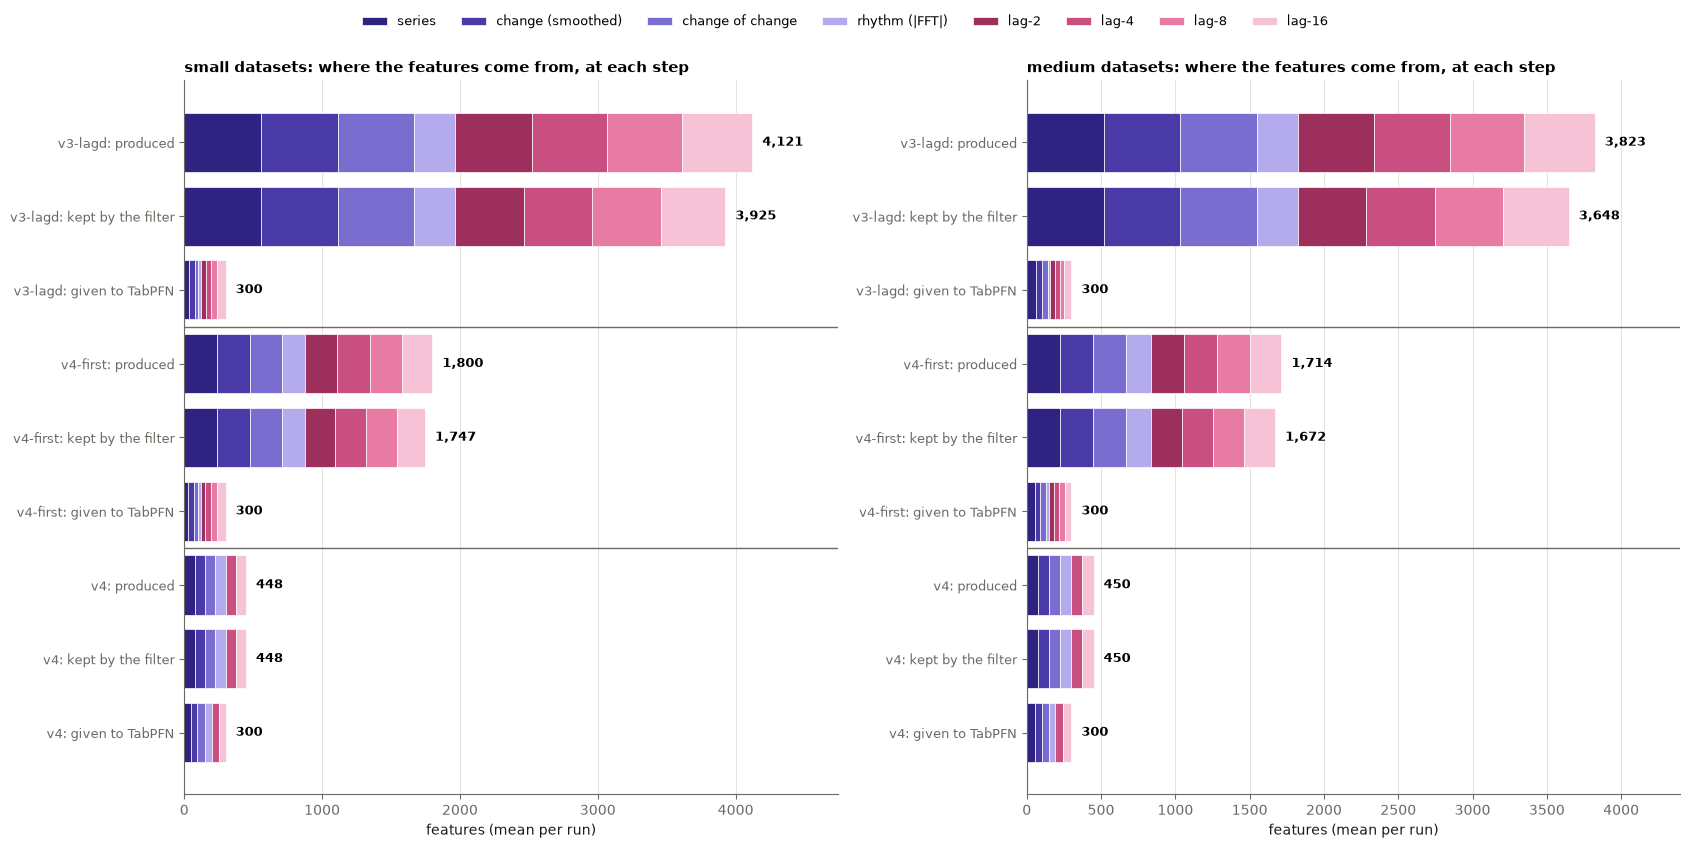

In [12]:
# 10b: the funnel: produced -> kept by the filter -> given to TabPFN, split by where the features come from
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
for ax, group in zip(axes, GROUPS):
    rows = [(f"{run}: {STEPS[step]}", feature_classes(group, run).loc[step].groupby(level="source").sum())
            for run in FEATURE_RUNS for step in STEPS]
    y = np.arange(len(rows))[::-1]
    left = np.zeros(len(rows))
    for source in SOURCES:
        values = np.array([counts.get(source, 0) for _, counts in rows])
        ax.barh(y, values, left=left, color=SOURCE_COLORS[source], edgecolor="white", linewidth=0.5,
                label=source if ax is axes[0] else None)
        left += values
    for yy, total in zip(y, left):
        ax.text(total, yy, f"  {total:,.0f}", va="center", fontsize=9, fontweight="bold")
    for k in range(1, len(FEATURE_RUNS)):                           # lines between the three runs
        ax.axhline(len(rows) - 3 * k - 0.5, color=MUTED, linewidth=1)
    ax.set_yticks(y, [name for name, _ in rows], fontsize=9)
    ax.set_xlim(0, left.max() * 1.15)
    ax.set_xlabel("features (mean per run)")
    ax.set_title(f"{group} datasets: where the features come from, at each step", loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
fig.legend(loc="upper center", ncol=8, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

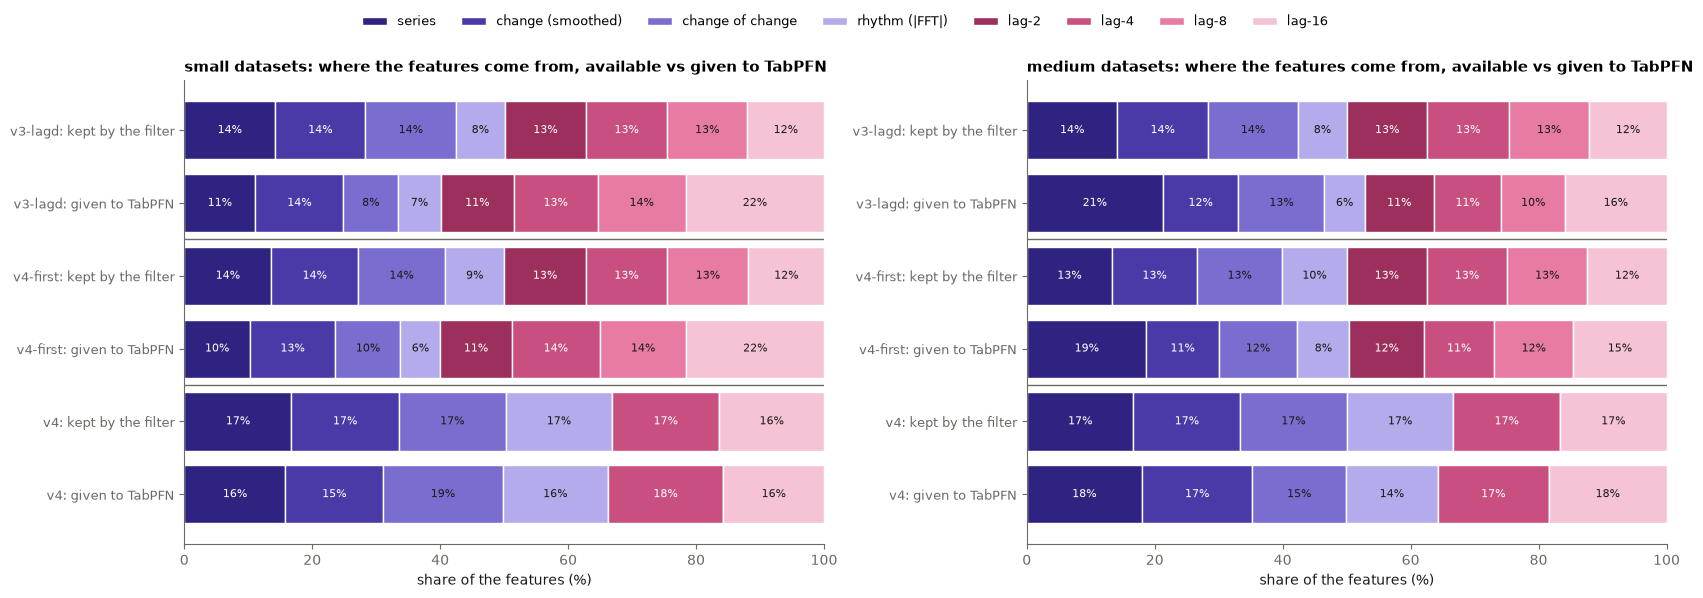

In [13]:
# 10b-2: the same as shares: TabPFN's 300 are too few to see their sources in 10b
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, group in zip(axes, GROUPS):
    rows = []
    for run in FEATURE_RUNS:
        classes = feature_classes(group, run)
        for step in ["2 kept by the filters", "3 chosen by TabPFN"]:
            sources = classes.loc[step].groupby(level="source").sum()
            rows.append((f"{run}: {STEPS[step]}", 100 * sources / sources.sum()))
    y = np.arange(len(rows))[::-1]
    left = np.zeros(len(rows))
    for source in SOURCES:
        values = np.array([share.get(source, 0) for _, share in rows])
        bars = ax.barh(y, values, left=left, color=SOURCE_COLORS[source], edgecolor="white",
                       label=source if ax is axes[0] else None)
        ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 5 else "" for v in values], label_type="center", fontsize=8,
                     color="white" if source in ("series", "change (smoothed)", "lag-2", "lag-4") else TEXT)
        left += values
    for k in range(1, len(FEATURE_RUNS)):
        ax.axhline(len(rows) - 2 * k - 0.5, color=MUTED, linewidth=1)
    ax.set_yticks(y, [name for name, _ in rows], fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_xlabel("share of the features (%)")
    ax.set_title(f"{group} datasets: where the features come from, available vs given to TabPFN", loc="left")
    ax.grid(False)
fig.legend(loc="upper center", ncol=8, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

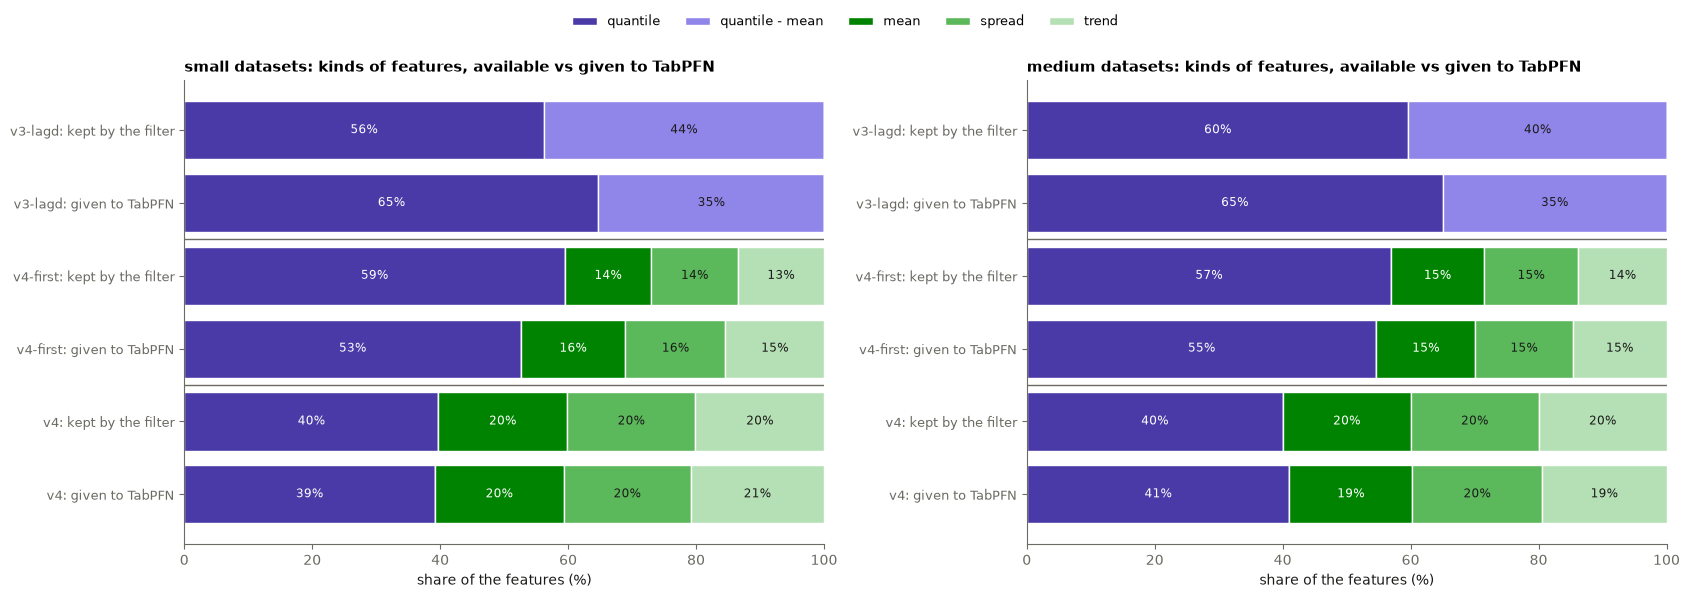

In [14]:
# 10c: which kinds of features are given to TabPFN, as a share of what is available and of what it gets
KINDS = {"quantile": "#4a3aa7", "quantile - mean": "#9085e9", "mean": "#008300", "spread": "#5bb85b", "trend": "#b5e0b5"}
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, group in zip(axes, GROUPS):
    rows = []
    for run in FEATURE_RUNS:
        classes = feature_classes(group, run)
        for step in ["2 kept by the filters", "3 chosen by TabPFN"]:
            kinds = classes.loc[step].groupby(level="kind").sum()
            rows.append((f"{run}: {STEPS[step]}", 100 * kinds / kinds.sum()))
    y = np.arange(len(rows))[::-1]
    left = np.zeros(len(rows))
    for kind, color in KINDS.items():
        values = np.array([share.get(kind, 0) for _, share in rows])
        bars = ax.barh(y, values, left=left, color=color, edgecolor="white", label=kind if ax is axes[0] else None)
        ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 4 else "" for v in values], label_type="center", fontsize=8.5,
                     color="white" if kind in ("quantile", "mean") else TEXT)
        left += values
    for k in range(1, len(FEATURE_RUNS)):
        ax.axhline(len(rows) - 2 * k - 0.5, color=MUTED, linewidth=1)
    ax.set_yticks(y, [name for name, _ in rows], fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_xlabel("share of the features (%)")
    ax.set_title(f"{group} datasets: kinds of features, available vs given to TabPFN", loc="left")
    ax.grid(False)
fig.legend(loc="upper center", ncol=5, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 10. Fewer features (v4, v4-nofilter), ANOVA alone (v4-wide) and three ways to pick TabPFN's features

Section 9 showed that the features given to TabPFN are a small copy of everything produced: no kind is clearly
preferred, so most of the ~1,750 produced features only cost time. **v4** produces about 450 instead, keeping every
kind: the new extractor with 4 levels of pieces instead of 5 and a fixed 2 quantiles per piece (min and max; the
mean, spread and trend stay), and only 2 lag-d differences (d = 4 and 16) instead of 4
(`--quant tabpfn -m 4 --quantiles 2 --lags 4,16`). All of them pass the lag-d filter.

TabPFN's 300 (or 200) features are then picked in three ways (`--tabpfn_rank`):
- **ExtraTrees**: the most important features in an ExtraTrees fit (as in every run so far);
- **ANOVA**: the highest ANOVA F-scores, each feature judged alone (milliseconds instead of a forest);
- **both**: ANOVA drops the worse half of the features beyond the budget, ExtraTrees picks from the rest.

**v4-nofilter** goes further: about 252 features (3 levels of pieces, 3 quantiles per piece = min, median and max, plus
mean, spread and trend; lag-d 4 and 16: `-m 3 --quantiles 3 --lags 4,16`), no filter at all (`--prune none`) and
no ranking: the budget of 300 is larger than what is produced, so TabPFN gets every feature.

**v4-wide** goes the other way: the ~1,800 features of section 8 (`--quant tabpfn`, lag-d 2, 4, 8, 16), no lag-d filter
(`--prune none`), and ANOVA alone picks TabPFN's 200 (`--tabpfn_rank anova`); only with 2 passes x 200.

Compared with the two v4-first runs of section 8 (the new extractor with the cache, ~1,750 features, ExtraTrees
ranking), on the same 15 runs per list. Top: accuracy, with the number of runs where each version is better / equal /
worse than v4-first; bottom: time per run, split into the feature transforms, the ranking + TabPFN's fit, and the
prediction.

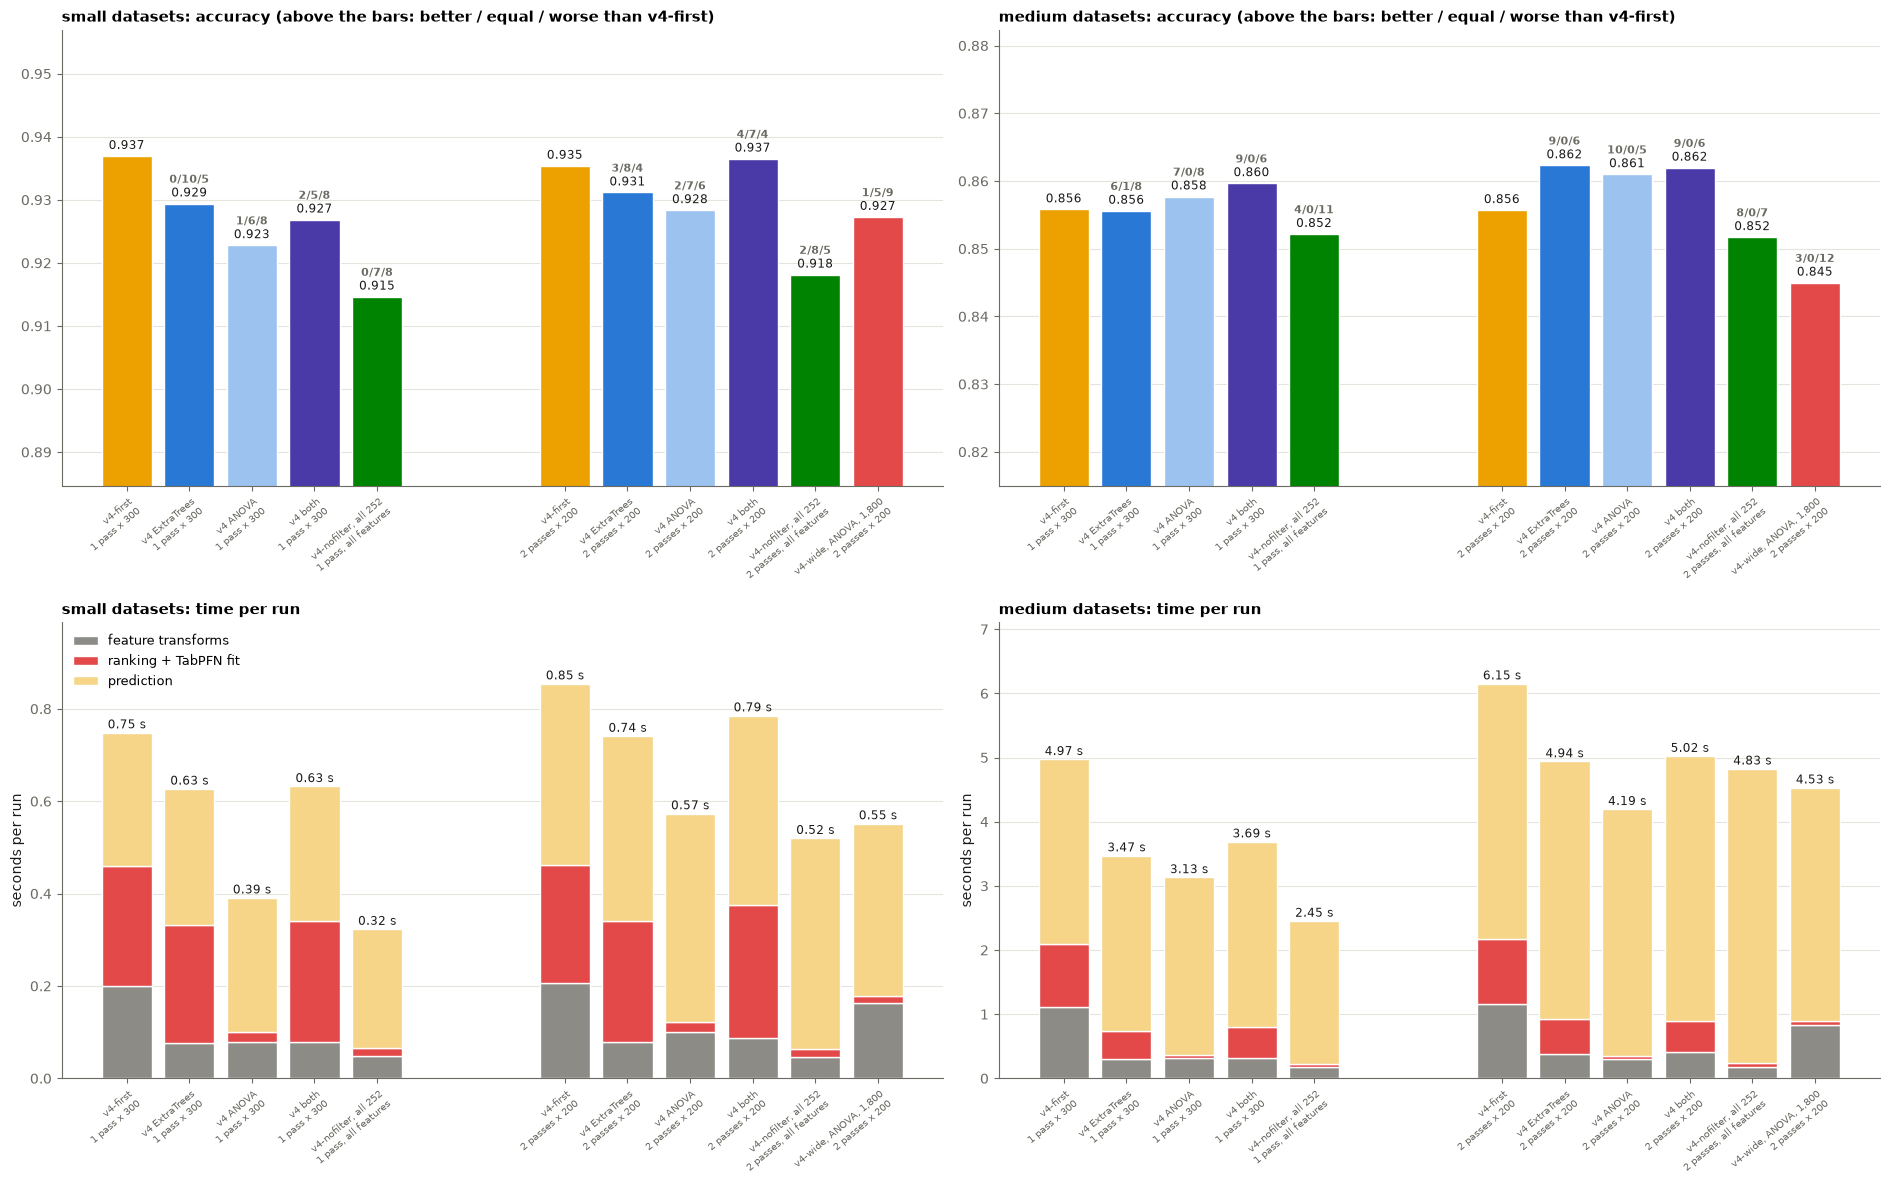

In [15]:
RANKINGS = {"v4-first": None, "v4 ExtraTrees": "extratrees", "v4 ANOVA": "anova", "v4 both": "both",
            "v4-nofilter, all 252": "nofilter", "v4-wide, ANOVA, 1,800": "wide"}
RANK_COLORS = [COLORS["tabpfn"], "#2a78d6", "#9cc3ef", "#4a3aa7", "#008300", "#e34948"]
TIME_PARTS = {"feature transforms": "#8c8b85", "ranking + TabPFN fit": "#e34948", "prediction": "#f6d488"}
SETTINGS = {"tabpfn-e1f300": "1 pass x 300", "tabpfn-e2f200": "2 passes x 200"}

def v4_runs(rank, config, group):
    """v4-first (rank None, section 8), v4 with the given ranking, v4-nofilter (all its features, with the same number
    of passes: 1 pass for 1 x 300, 2 passes for 2 x 200) or v4-wide."""
    if rank is None:
        return lagd_cached(config, group, True)
    if rank == "nofilter":
        return load(f"v4-nofilter_{config[:9]}_smoke-{group}_allcores-gpu.csv")   # "tabpfn-e1f300" -> "tabpfn-e1"
    if rank == "wide":
        return load(f"v4-wide_{config}-anova_smoke-{group}_allcores-gpu.csv")
    return load(f"v4_{config}-{rank}_smoke-{group}_allcores-gpu.csv")

fig, axes = plt.subplots(2, 2, figsize=(19, 12))
for col, group in enumerate(GROUPS):
    x_pos, labels = [], []
    for s, (config, setting) in enumerate(SETTINGS.items()):
        reference = v4_runs(None, config, group).set_index(key)
        for j, (name, rank) in enumerate(RANKINGS.items()):
            if rank == "wide" and config != "tabpfn-e2f200":                 # v4-wide only has 2 passes x 200
                continue
            runs = v4_runs(rank, config, group)
            x = s * (len(RANKINGS) + 1) + j                       # a gap between the two settings
            x_pos.append(x)
            shown = setting.split(" x ")[0] + ", all features" if rank == "nofilter" else setting
            labels.append(f"{name}\n{shown}")
            # top: accuracy, and better / equal / worse than v4-first on the same runs
            ax = axes[0, col]
            accuracy = runs["accuracy"].mean()
            bar = ax.bar(x, accuracy, 0.8, color=RANK_COLORS[j], edgecolor="white")
            ax.bar_label(bar, fmt="{:.3f}", padding=3, fontsize=8.5, color=TEXT)
            if rank is not None:
                b, e, w = wdl_counts(runs.set_index(key)["accuracy"] - reference["accuracy"])
                ax.annotate(f"{b}/{e}/{w}", (x, accuracy), xytext=(0, 15), textcoords="offset points", ha="center",
                            fontsize=8, color=MUTED, fontweight="bold")
            # bottom: the time, in its three parts
            ax = axes[1, col]
            parts = [runs["transform_time"].mean(), (runs["time_select"] + runs["time_fit"]).mean(), runs["time_predict"].mean()]
            bottom = 0.0
            for (part, color), seconds in zip(TIME_PARTS.items(), parts):
                ax.bar(x, seconds, 0.8, bottom=bottom, color=color, edgecolor="white",
                       label=part if (s, j) == (0, 0) else None)
                bottom += seconds
            ax.annotate(f"{bottom:.2f} s", (x, bottom), xytext=(0, 3), textcoords="offset points", ha="center",
                        fontsize=8.5, color=TEXT)
    for row in range(2):
        axes[row, col].set_xticks(x_pos, labels, fontsize=7.5, rotation=40, ha="right", rotation_mode="anchor")
    values = [p.get_height() for p in axes[0, col].patches]
    axes[0, col].set_ylim(min(values) - 0.03, min(1.0, max(values) + 0.02))
    axes[0, col].set_title(f"{group} datasets: accuracy (above the bars: better / equal / worse than v4-first)", loc="left")
    axes[1, col].set_ylim(0, axes[1, col].get_ylim()[1] * 1.1)
    axes[1, col].set_ylabel("seconds per run")
    axes[1, col].set_title(f"{group} datasets: time per run", loc="left")
axes[1, 0].legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

Note: the accuracy axes do not start at 0, to make the differences visible; the time axes start at 0.

## 11. Where we started and where we ended

The two v1 references (QUANT's features, TabPFN's model built for every run) next to the best cheap TabPFN of
section 10: **v4 + both** with 2 passes x 200 features (about 450 features from the new extractor and lag-d 4 and
16; ANOVA keeps 325 of them, ExtraTrees picks the 200 given to TabPFN; with the model cache), on the same 15 runs
per list. Above each bar: its change against QUANT + ExtraTrees (accuracy) or its time as a multiple of ExtraTrees'
time.

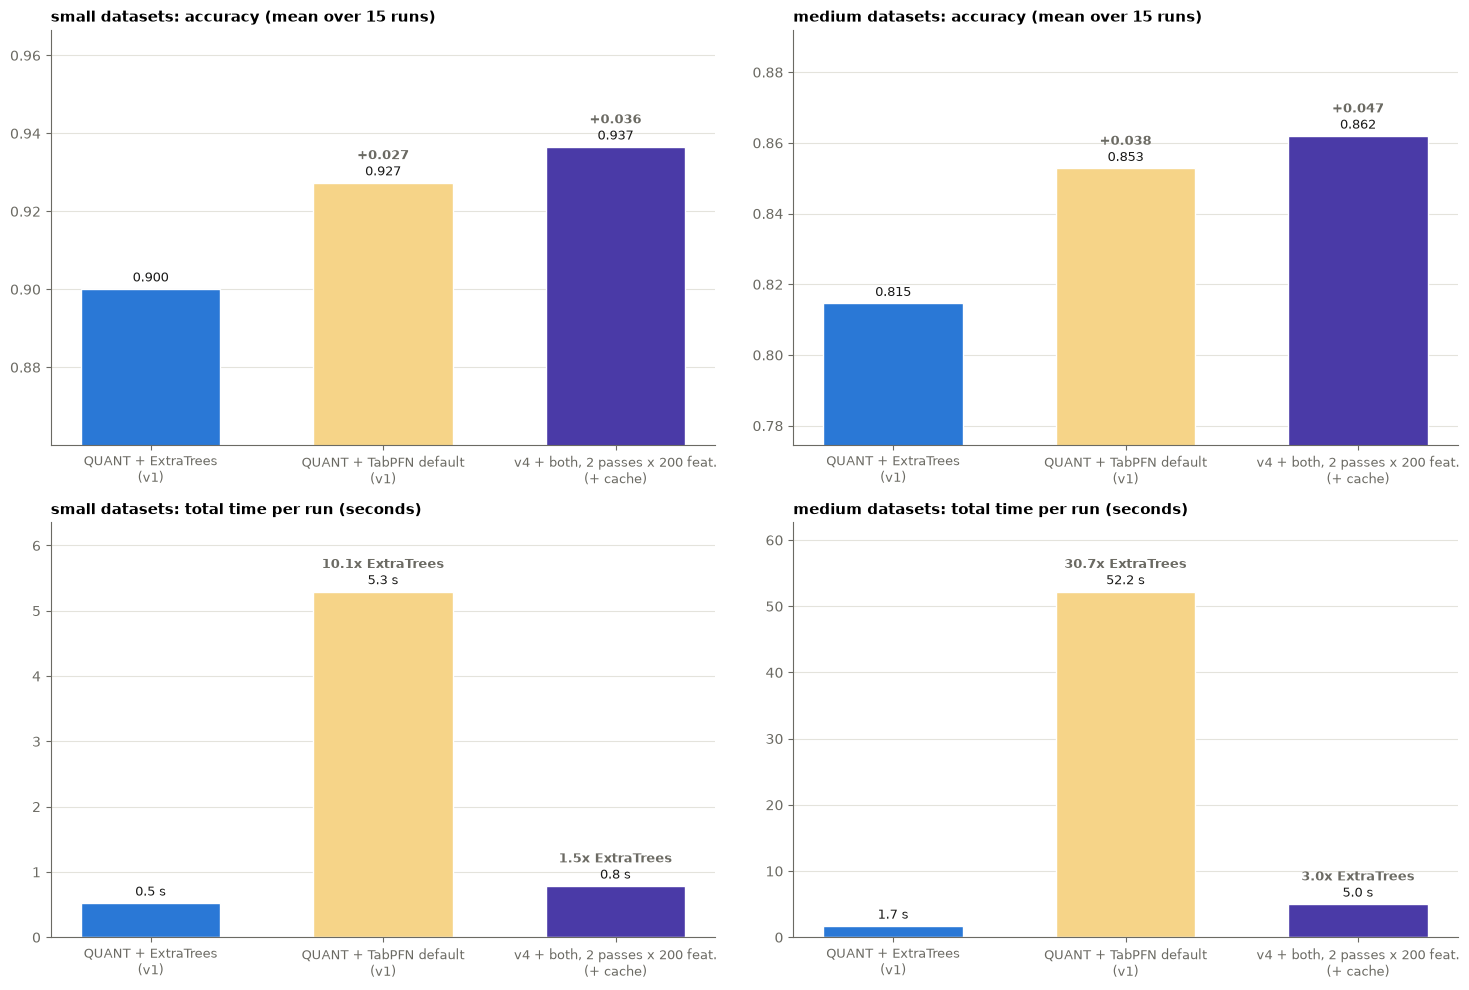

In [16]:
FINAL = ["QUANT + ExtraTrees\n(v1)", "QUANT + TabPFN default\n(v1)", "v4 + both, 2 passes x 200 feat.\n(+ cache)"]
FINAL_COLORS = [COLORS["extratrees"], "#f6d488", "#4a3aa7"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for col, group in enumerate(GROUPS):
    v1 = V1[group]
    runs = [v1[v1["classifier"] == "extratrees"], v1[v1["classifier"] == "tabpfn"],
            load(f"v4_tabpfn-e2f200-both_smoke-{group}_allcores-gpu.csv")]
    for row, (metric, title, fmt) in enumerate([("accuracy", "accuracy (mean over 15 runs)", "{:.3f}"),
                                                ("total_time", "total time per run (seconds)", "{:.1f} s")]):
        ax = axes[row, col]
        values = [r[metric].mean() for r in runs]
        bars = ax.bar(range(len(FINAL)), values, 0.6, color=FINAL_COLORS, edgecolor="white")
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9.5, color=TEXT)
        for k in range(1, len(FINAL)):  # against QUANT + ExtraTrees, above the value
            text = signed(values[k] - values[0]) if metric == "accuracy" else f"{values[k] / values[0]:.1f}x ExtraTrees"
            ax.annotate(text, (k, values[k]), xytext=(0, 17), textcoords="offset points", ha="center", fontsize=9,
                        color=MUTED, fontweight="bold")
        if metric == "accuracy":
            ax.set_ylim(min(values) - 0.04, min(1.0, max(values) + 0.03))
        else:
            ax.set_ylim(0, max(values) * 1.2)
        ax.set_xticks(range(len(FINAL)), FINAL, fontsize=9)
        ax.set_title(f"{group} datasets: {title}", loc="left")
fig.tight_layout()
plt.show()

Note: the accuracy axes do not start at 0, to make the differences visible; the time axes start at 0.

## 12. Conclusions

- **The best cheap TabPFN on QUANT's original extractor: 1 pass, 300 features, on v2-lagd's features (v3-lagd).** On the medium datasets it keeps almost all
  of TabPFN's accuracy (0.849 vs 0.853 for the default) at 7.7 s instead of 52.2 s per run, about 7x faster. On the
  small datasets it is even slightly more accurate than the default (0.932 vs 0.927) and 1.7x faster (3.1 s vs 5.3 s).
- **v2-lagd's features help TabPFN only on the small datasets.** There, most v3-lagd versions beat their v3-quant
  twins (default: 0.944 vs 0.927; 2 passes x 200 features: 0.943 vs 0.931). On the medium datasets the two feature
  sets are equal (default: 0.854 vs 0.853).
- **1 pass with fewer features costs little.** On the medium datasets 1 pass with 500, 400, 300, 200 or 100 features
  gives 0.844 to 0.849, only 0.004 to 0.009 below the default, at 7 to 11 s per run. The number of features matters
  less than the number of passes; 300 was the best on both lists.
- **Against the original QUANT (ExtraTrees):** the chosen TabPFN is more accurate on both lists (+0.032 small, +0.035
  medium; better in 12 of 15 and 14 of 15 runs) but slower (6x on small: 3.1 s vs 0.5 s; 4.5x on medium: 7.7 s vs
  1.7 s).
- **Against QUANT + TabPFN's default:** about as accurate (+0.005 small, -0.003 medium) at a fraction of the time;
  on the medium datasets it is a little worse in 11 of 15 runs, by small amounts.
- **Where the time goes:** fewer passes cut the time almost in proportion (medium: 50 s for 8 passes, 28 s for 4, 16 s
  for 2, 10 s for 1); fewer features cut it further (8 passes: 50 s with 500 features, 22 s with 200). The
  training-context cap (at most 1,000 cases) saves 30-40% of the time but costs about 0.01 accuracy, so it is not
  worth it at these sizes.
- **Small vs medium:** the ranking is the same on both lists (TabPFN above ExtraTrees, and the cheap version close to
  the default), but on the small datasets TabPFN's fixed start-up cost of about 3 s dominates, so the cheap versions
  save little time there; the savings matter on the medium datasets. Most of that start-up cost is the model
  being rebuilt for every run (section 7).
- **Building the model once (section 7) makes TabPFN faster again, with identical accuracy** (120 of 120 runs).
  It saves about 2 s per run: the chosen version (1 pass x 300 features on v2-lagd) takes 1.0 s instead of 3.1 s on
  the small datasets (about 2x ExtraTrees' 0.5 s instead of 6x) and 6.3 s instead of 7.7 s on the medium ones; 2 x
  200 features on QUANT 1.0 s instead of 3.0 s (small) and 5.9 s instead of 8.7 s (medium). For the slow default
  (about 50 s on medium) it makes no real difference. The times of sections 2 to 6 are without the cache.
- **A feature extractor made for TabPFN (section 8) helps on the medium datasets.** `quant_tabpfn.py` produces less
  than half the features (medium: 1,714 instead of 3,823 per run, small: 1,800 instead of 4,121) and makes TabPFN
  faster (medium, 1 pass x 300: 5.0 s instead of 6.4 s) and more accurate on the medium datasets: 0.856 instead of
  0.849 (1 x 300) and 0.856 instead of 0.847 (2 x 200), better in 12 of 15 runs both times. On the small datasets it
  is about the same (1 x 300: 0.937 vs 0.932, better 3, equal 9, worse 3; 2 x 200: 0.935 vs 0.943).
- **Which features matter (section 9):** the lag-d filter drops only lag-d features (about 200 per run with the
  original extractor, about 50 with the new one). TabPFN takes its 300 from every source, but prefers the
  longest lag (lag-16: 22% of its choice on the small datasets, 12% of what is available) and the series itself on
  the medium datasets (19-21% vs 13-14%). With the original extractor it prefers the plain quantiles (65% of its
  choice); with the new one, the added mean, spread and trend make up 45-47% of its choice, as much as of what is
  available, so the new summaries are used as much as the quantiles.
- **v4: a quarter of the features is enough on the medium datasets (section 10).** With about 450 features
  instead of ~1,750, TabPFN is as accurate or more on the medium datasets (0.856 to 0.862 vs 0.856) and 20-35%
  faster (1 x 300: 3.1 to 3.7 s instead of 5.0 s); on the small datasets it loses a little (0.923 to 0.937 vs
  0.935 to 0.937). Most of the saving is in the transforms and the ranking, not in TabPFN itself.
- **How TabPFN's features are picked matters little for accuracy, a lot for time.** ANOVA, ExtraTrees and both
  are within 0.006 of each other on every list; ANOVA ranks in about 0.04 s instead of 0.4-0.5 s, so v4 + ANOVA is
  the fastest version (medium, 1 x 300: 0.858 at 3.1 s, 1.8x ExtraTrees' time). The best on the medium datasets is
  v4 + 2 passes x 200 (0.861 to 0.862, better than v4-first in 9-10 of 15 runs) at 4.2 to 5.0 s.
- **Fewer features without any filter (v4-nofilter) is the fastest, but loses accuracy.** With about 252 features and no
  filter or ranking, TabPFN takes 0.32 s on the small and 2.45 s on the medium datasets (1 pass), the fastest
  versions here (1.4x ExtraTrees' time on medium), but is less accurate: 0.915 and 0.852, against 0.937 and 0.856
  for v4-first and 0.923 and 0.858 for v4 + ANOVA. Producing more features and then picking the best 300 works
  better than producing only 252: the coarser pieces (3 levels) lose detail that TabPFN uses.
- **ANOVA alone on the large feature set (v4-wide) is the worst choice.** With ~1,800 features and only ANOVA to pick
  TabPFN's 200, accuracy drops to 0.927 (small) and 0.845 (medium), worse than v4-first in 9 and 12 of 15 runs, and
  below v4 + ANOVA on 450 features (0.928 and 0.861). ANOVA judges each feature alone, so near-copies of a good
  feature all score high and fill the budget; with v4's 450 features there are few near-copies, and ANOVA works.
  The ranking itself is cheap either way (0.02 to 0.06 s).
- **Where we ended (section 11):** the best cheap TabPFN is v4 + both with 2 passes x 200 features (about 450
  features, ANOVA then ExtraTrees pick 200, model cache): 0.937 on the small datasets (+0.036 over QUANT +
  ExtraTrees, +0.010 over TabPFN's default) at 0.8 s per run (1.5x ExtraTrees' time, against 10.1x for the
  default), and 0.862 on the medium datasets (+0.047, +0.009 over the default) at 5.0 s (3.0x, against 30.7x).

Caveat: smoke tests (5 datasets x 3 resamples per list); the differences between TabPFN versions (a few thousandths)
are smaller than the spread between resamples, only the gap to ExtraTrees (about +0.03) is clearly larger.